In [1]:
import os
import time
import requests
from io import BytesIO
from math import floor, pi, radians
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from matplotlib.colors import LogNorm, ListedColormap
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score
from scipy.stats import spearmanr
from scipy.spatial import procrustes
from scipy.spatial.distance import pdist
import umap

SEED = 42
DATA_PATH = "train.csv"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

ESB = (40.756724, -73.983806)
JFK = (40.647929, -73.777813)
EWR = (40.689442, -74.173242)

def haversine_np(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    return 6367 * 2 * np.arcsin(np.sqrt(a))

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Question 1: Data cleaning

In [2]:
df = pd.read_csv(DATA_PATH,
                 parse_dates=["pickup_datetime", "dropoff_datetime"])

print("Raw shape:", df.shape)
print(df.dtypes)
df.head()

Raw shape: (1458644, 11)
id                               str
vendor_id                      int64
pickup_datetime       datetime64[us]
dropoff_datetime      datetime64[us]
passenger_count                int64
pickup_longitude             float64
pickup_latitude              float64
dropoff_longitude            float64
dropoff_latitude             float64
store_and_fwd_flag               str
trip_duration                  int64
dtype: object


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982,40.768,-73.965,40.766,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980,40.739,-73.999,40.731,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979,40.764,-74.005,40.710,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010,40.720,-74.012,40.707,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973,40.793,-73.973,40.783,N,435


In [3]:
#Pre-cleaning diagnostics
df["distance_km"] = haversine_np(df.pickup_longitude, df.pickup_latitude,
                                 df.dropoff_longitude, df.dropoff_latitude)
df["speed_kmh"] = df["distance_km"] / (df["trip_duration"] / 3600)

print(df[["trip_duration", "distance_km", "speed_kmh"]].describe(percentiles=[.01, .5, .99]))
print("\nNegative/zero durations:", (df.trip_duration <= 0).sum())
print("Durations > 6 h     :", (df.trip_duration > 6 * 3600).sum())
print("Zero-distance trips :", (df.distance_km == 0).sum())
print("Speed > 100 km/h    :", (df.speed_kmh > 100).sum())
print("Speed < 1 km/h      :", (df.speed_kmh < 1).sum())
print("Pickup outside NYC  :",
      ((~df.pickup_longitude.between(-74.3, -73.7)) |
       (~df.pickup_latitude.between(40.5, 41.0))).sum())
print("\npassenger_count distribution:\n", df.passenger_count.value_counts().sort_index())

#Show the effect of each filter
def summarize(name, mask):
    kept = mask.sum()
    print(f"{name:<38} kept {kept:>10,}  ({kept/len(df)*100:5.2f}%)")
    return mask

# 1. sensible duration: between 30 s and 6 h
m_dur  = df.trip_duration.between(30, 6 * 3600)
# 2. plausible average speed: between 1 and 100 km/h
m_spd  = df.speed_kmh.between(1, 100)
# 3. pickup and dropoff inside the NYC bounding box
m_box  = (df.pickup_longitude.between(-74.3, -73.7) &
          df.pickup_latitude .between(40.5, 41.0) &
          df.dropoff_longitude.between(-74.3, -73.7) &
          df.dropoff_latitude .between(40.5, 41.0))
# 4. non-zero distance (removes cancelled / GPS-stuck trips)
m_dist = df.distance_km > 0
# 5. valid passenger count
m_pass = df.passenger_count.between(1, 6)

print("\n--- Filter retention ---")
summarize("Duration 30 s – 6 h", m_dur)
summarize("Speed 1 – 100 km/h", m_spd)
summarize("Coordinates in NYC bbox", m_box)
summarize("Distance > 0", m_dist)
summarize("Passenger count 1–6", m_pass)

mask = m_dur & m_spd & m_box & m_dist & m_pass
df_clean = df.loc[mask].copy()

print("\nRows before cleaning:", f"{len(df):,}")
print("Rows after  cleaning:", f"{len(df_clean):,}",
      f"({len(df_clean)/len(df)*100:.2f}% retained)")

print("\nCleaned summary:")
print(df_clean[["trip_duration", "distance_km", "speed_kmh"]].describe())

       trip_duration   distance_km     speed_kmh
count  1,458,644.000 1,458,644.000 1,458,644.000
mean         959.492         3.439        14.414
std        5,237.432         4.294        14.968
min            1.000         0.000         0.000
1%            87.000         0.139         1.393
50%          662.000         2.092        12.784
99%        3,440.000        20.774        40.720
max    3,526,282.000     1,240.130     9,269.014

Negative/zero durations: 0
Durations > 6 h     : 2061
Zero-distance trips : 5897
Speed > 100 km/h    : 175
Speed < 1 km/h      : 13241
Pickup outside NYC  : 256

passenger_count distribution:
 passenger_count
0         60
1    1033540
2     210318
3      59896
4      28404
5      78088
6      48333
7          3
8          1
9          1
Name: count, dtype: int64

--- Filter retention ---
Duration 30 s – 6 h                    kept  1,451,801  (99.53%)
Speed 1 – 100 km/h                     kept  1,445,228  (99.08%)
Coordinates in NYC bbox              


Rows before cleaning: 1,458,644
Rows after  cleaning: 1,442,031 (98.86% retained)

Cleaned summary:
       trip_duration   distance_km     speed_kmh
count  1,442,031.000 1,442,031.000 1,442,031.000
mean         838.803         3.451        14.475
std          656.254         3.884         7.620
min           30.000         0.009         1.000
25%          400.000         1.251         9.222
50%          664.000         2.112        12.853
75%        1,074.000         3.896        17.884
max       21,411.000        47.735        99.469


# Question 2: Feature generation

In [4]:
df_clean["pickup_date"]   = df_clean.pickup_datetime.dt.date
df_clean["pickup_hour"]   = df_clean.pickup_datetime.dt.hour
df_clean["pickup_dow"]    = df_clean.pickup_datetime.dt.dayofweek          # Mon=0 … Sun=6
df_clean["day_name"]      = df_clean.pickup_datetime.dt.day_name()
df_clean["is_weekend"]    = df_clean.pickup_dow >= 5
# (distance_km and speed_kmh were created before cleaning in Cell 1)

# sanity check
print(df_clean[["pickup_datetime","distance_km","trip_duration",
                "speed_kmh","pickup_dow","day_name","pickup_hour"]].head())

print("\nDay-of-week counts:")
print(df_clean.day_name.value_counts().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]))

      pickup_datetime  distance_km  trip_duration  speed_kmh  pickup_dow  \
0 2016-03-14 17:24:55        1.498            455     11.849           0   
1 2016-06-12 00:43:35        1.804            663      9.798           6   
2 2016-01-19 11:35:24        6.381           2124     10.815           1   
3 2016-04-06 19:32:31        1.485            429     12.458           2   
4 2016-03-26 13:30:55        1.188            435      9.830           5   

    day_name  pickup_hour  
0     Monday           17  
1     Sunday            0  
2    Tuesday           11  
3  Wednesday           19  
4   Saturday           13  

Day-of-week counts:
day_name
Monday       185308
Tuesday      200459
Wednesday    207871
Thursday     216049
Friday       220968
Saturday     218393
Sunday       192983
Name: count, dtype: int64


# Question 3: Time-based analysis

## Q3.1: Which day of the week is the most popular?

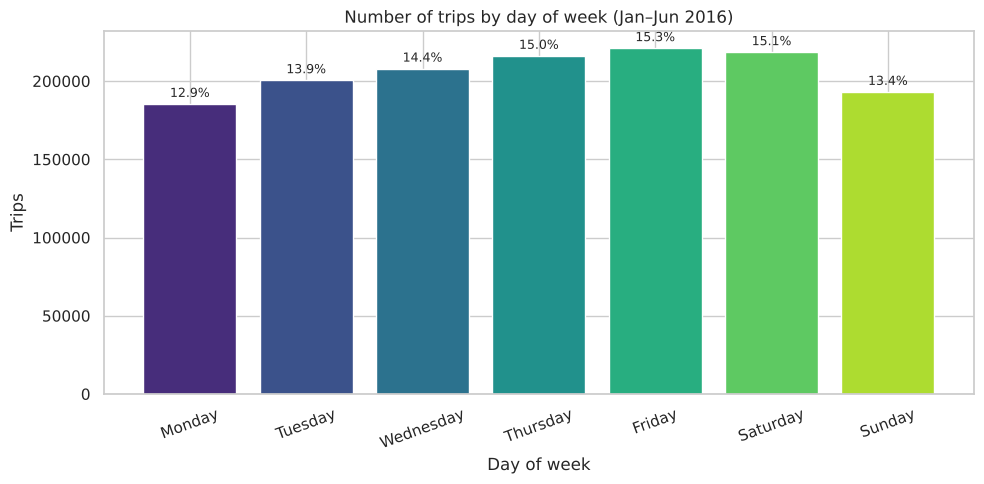

            trips  share_pct
day_name                    
Monday     185308     12.850
Tuesday    200459     13.901
Wednesday  207871     14.415
Thursday   216049     14.982
Friday     220968     15.323
Saturday   218393     15.145
Sunday     192983     13.383

Most popular day: Friday (220,968 trips)
Least popular day: Monday (185,308 trips)


In [5]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
counts = df_clean.day_name.value_counts().reindex(order)
share  = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(order, counts.values, color=sns.color_palette("viridis", 7))
ax.bar_label(bars, labels=[f"{s:.1f}%" for s in share], padding=3, fontsize=9)
ax.set_title("Number of trips by day of week (Jan–Jun 2016)")
ax.set_ylabel("Trips")
ax.set_xlabel("Day of week")
plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/q3_1_day_of_week.png", dpi=150); plt.show()

print(counts.to_frame("trips").assign(share_pct=share))
print("\nMost popular day:", counts.idxmax(), f"({counts.max():,} trips)")
print("Least popular day:", counts.idxmin(), f"({counts.min():,} trips)")

## Q3.2: Most popular hour on each day

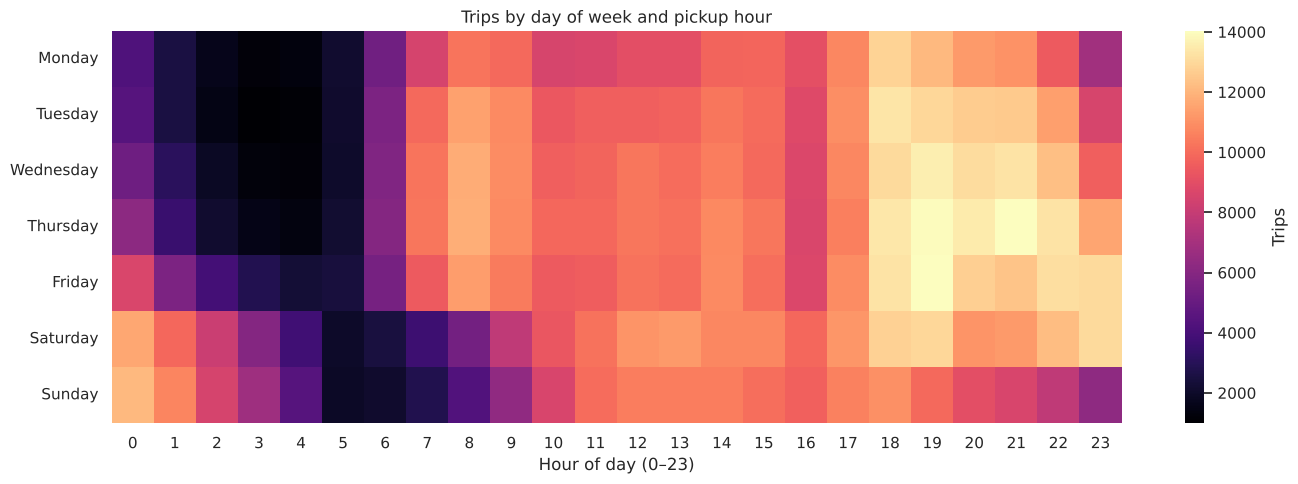

Peak hour per day:
 day_name
Monday       18
Tuesday      18
Wednesday    19
Thursday     21
Friday       19
Saturday     23
Sunday        0

Peak trip count per day:
 day_name
Monday       12829
Tuesday      13328
Wednesday    13573
Thursday     14019
Friday       14030
Saturday     13051
Sunday       12143


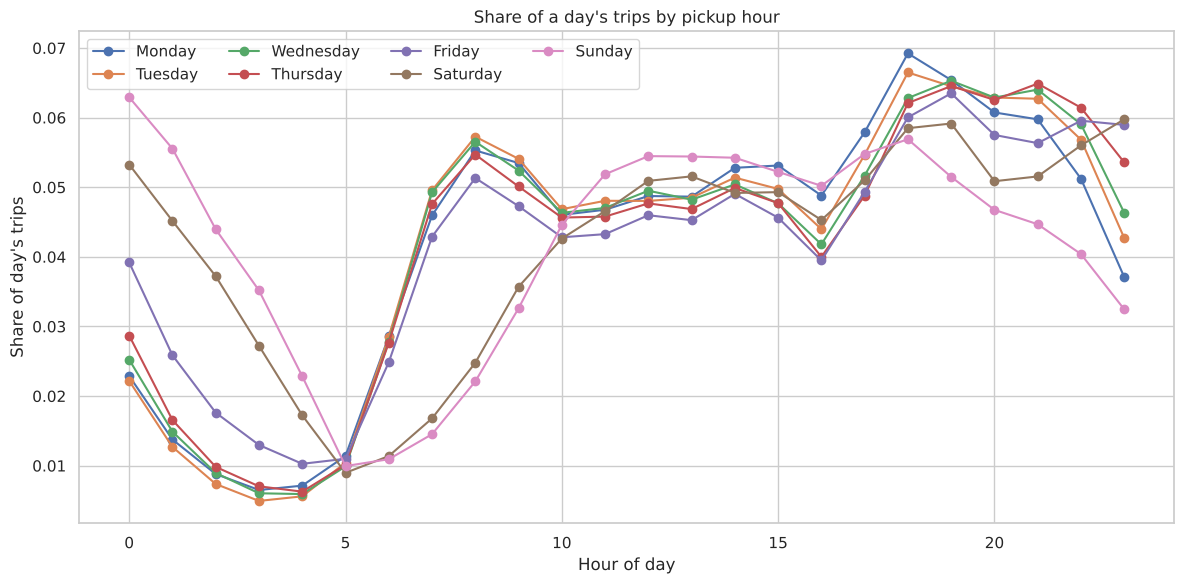

In [6]:
hour_day = (df_clean.groupby(["day_name","pickup_hour"])
                      .size()
                      .unstack("pickup_hour")
                      .reindex(order))

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(hour_day, cmap="magma", ax=ax, cbar_kws={"label": "Trips"})
ax.set_title("Trips by day of week and pickup hour")
ax.set_xlabel("Hour of day (0–23)"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/q3_2_heatmap.png", dpi=150); plt.show()

peak = hour_day.idxmax(axis=1)
print("Peak hour per day:\n", peak.to_string())
print("\nPeak trip count per day:\n", hour_day.max(axis=1).to_string())

# A second, clearer view: normalised hourly profile per day
profiles = hour_day.div(hour_day.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(12, 6))
for day in order:
    ax.plot(profiles.columns, profiles.loc[day], marker="o", label=day)
ax.set_title("Share of a day's trips by pickup hour")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Share of day's trips")
ax.legend(ncol=4); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q3_2_profiles.png", dpi=150); plt.show()

## Q3.3: Weekday vs weekend

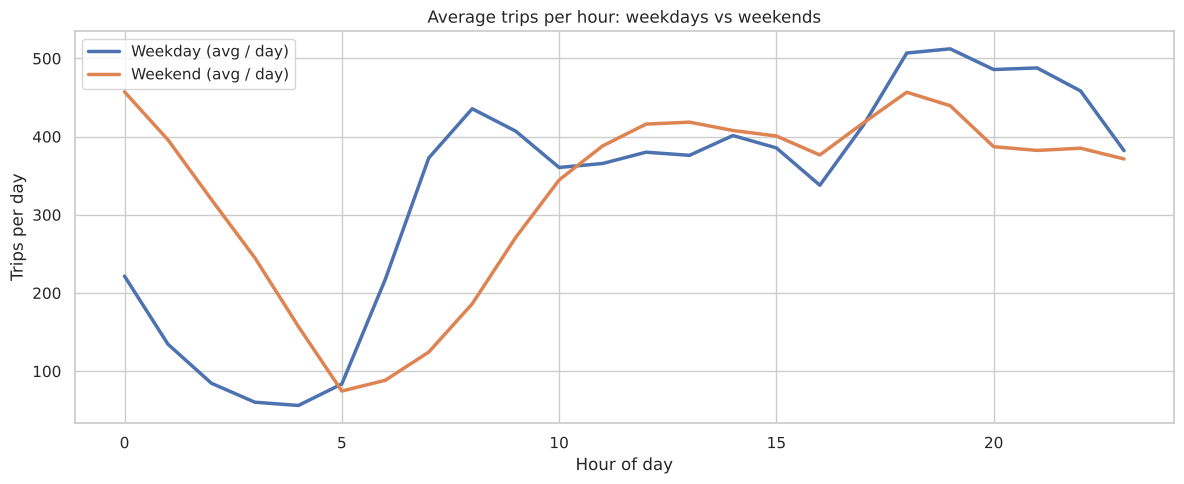

Weekday peak hour: 19 (512 trips/day)
Weekend peak hour: 0 (457 trips/day)


In [7]:
weekday_hours = (df_clean[~df_clean.is_weekend]
                 .groupby("pickup_hour").size())
weekend_hours = (df_clean[ df_clean.is_weekend]
                 .groupby("pickup_hour").size())

# Normalise to average trips per day so the two curves are comparable
n_week_days   = df_clean.loc[~df_clean.is_weekend, "pickup_date"].nunique()
n_weekend_days= df_clean.loc[ df_clean.is_weekend, "pickup_date"].nunique()
weekday_avg = weekday_hours / n_week_days
weekend_avg = weekend_hours / n_weekend_days

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(weekday_avg.index, weekday_avg.values, lw=2.5, label="Weekday (avg / day)")
ax.plot(weekend_avg.index, weekend_avg.values, lw=2.5, label="Weekend (avg / day)")
ax.set_title("Average trips per hour: weekdays vs weekends")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Trips per day")
ax.legend(); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q3_3_weekday_vs_weekend.png", dpi=150); plt.show()

print("Weekday peak hour:", int(weekday_avg.idxmax()),
      f"({weekday_avg.max():,.0f} trips/day)")
print("Weekend peak hour:", int(weekend_avg.idxmax()),
      f"({weekend_avg.max():,.0f} trips/day)")

## Q3.4: Major holidays

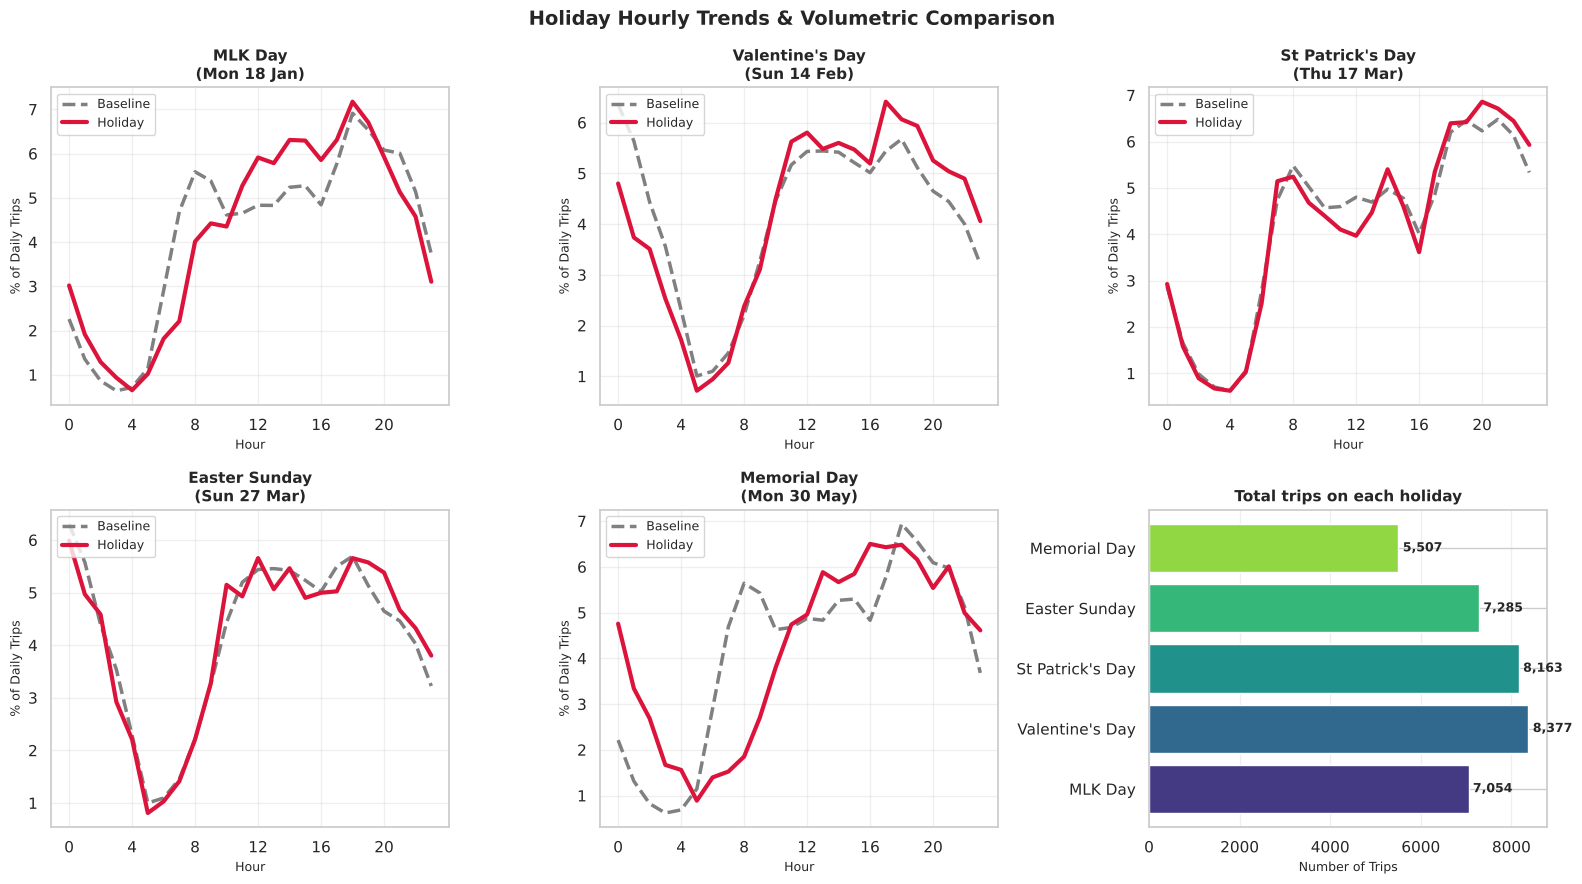

In [8]:
holidays = {
    "MLK Day\n(Mon 18 Jan)":              "2016-01-18",
    "Valentine's Day\n(Sun 14 Feb)":      "2016-02-14",
    "St Patrick's Day\n(Thu 17 Mar)":     "2016-03-17",
    "Easter Sunday\n(Sun 27 Mar)":        "2016-03-27",
    "Memorial Day\n(Mon 30 May)":         "2016-05-30",
}

def hourly_profile_for_date(frame, day):
    d = frame[frame.pickup_date == pd.Timestamp(day).date()]
    counts = d.groupby("pickup_hour").size().reindex(range(24), fill_value=0)
    return counts / counts.sum() if counts.sum() > 0 else counts

def baseline_for_weekday(frame, day):
    dow = pd.Timestamp(day).dayofweek
    other = frame[(frame.pickup_dow == dow) &
                  (frame.pickup_date != pd.Timestamp(day).date())]
    per_day = other.groupby(["pickup_date","pickup_hour"]).size().unstack(fill_value=0)
    mean_profile = per_day.mean(axis=0).reindex(range(24), fill_value=0)
    return mean_profile / mean_profile.sum() if mean_profile.sum() > 0 else mean_profile

# Set up a 2x3 grid. Subplots 1-5 show the hourly curves.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

for idx, (label, day) in enumerate(holidays.items()):
    ax = axes[idx]
    hol = hourly_profile_for_date(df_clean, day) * 100
    base = baseline_for_weekday(df_clean, day) * 100

    # Plot clean line profiles (without background bar charts)
    ax.plot(range(24), base.values, lw=2.5, label="Baseline", color="grey", linestyle="--")
    ax.plot(range(24), hol.values,  lw=3, label="Holiday", color="crimson")

    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.set_xlabel("Hour", fontsize=9)
    ax.set_ylabel("% of Daily Trips", fontsize=9)
    ax.set_xticks(range(0, 24, 4))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9, loc="upper left")

# 6th cell: total volume comparison bar chart
ax = axes[-1]
tot = {label.split("\n")[0]: df_clean[df_clean.pickup_date == pd.Timestamp(day).date()].shape[0]
       for label, day in holidays.items()}

bars = ax.barh(list(tot.keys()), list(tot.values()), color=sns.color_palette("viridis", len(tot)))
ax.set_title("Total trips on each holiday", fontsize=11, fontweight='bold')
ax.set_xlabel("Number of Trips", fontsize=9)
ax.grid(True, axis='x', alpha=0.3)

# Add values next to the bars
for bar in bars:
    width = bar.get_width()
    ax.text(width, bar.get_y() + bar.get_height()/2, f" {int(width):,}",
            va='center', ha='left', fontsize=9, fontweight='bold')

plt.suptitle("Holiday Hourly Trends & Volumetric Comparison", y=0.98, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q3_4_holidays.png", dpi=150)
plt.show()

## Q3.5: Average speed by hour of day

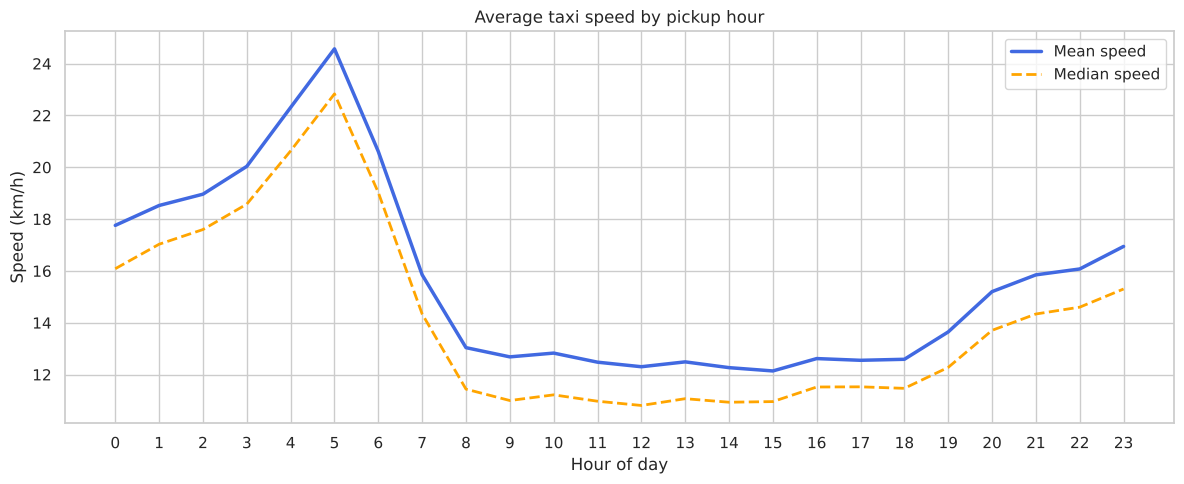

              mean  median  count
pickup_hour                      
0           17.760  16.090  52571
1           18.530  17.030  38060
2           18.960  17.600  27597
3           20.040  18.580  20571
4           22.310  20.630  15472
5           24.570  22.830  14752
6           20.610  19.030  32863
7           15.850  14.340  54915
8           13.040  11.440  66312
9           12.680  11.000  67005
10          12.830  11.220  64787
11          12.480  10.970  67707
12          12.300  10.810  71043
13          12.490  11.070  70650
14          12.270  10.930  73387
15          12.140  10.960  70965
16          12.620  11.520  63494
17          12.550  11.530  75592
18          12.590  11.470  89650
19          13.650  12.280  89450
20          15.200  13.710  83286
21          15.850  14.340  83303
22          16.080  14.600  79621
23          16.950  15.300  68978

Fastest hour (mean): 5 (24.6 km/h)
Slowest hour (mean): 15 (12.1 km/h)


In [9]:
speed_by_hour = (df_clean.groupby("pickup_hour")["speed_kmh"]
                 .agg(["mean", "median", "count"]))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(speed_by_hour.index, speed_by_hour["mean"], lw=2.5, label="Mean speed", color="royalblue")
ax.plot(speed_by_hour.index, speed_by_hour["median"], lw=2, ls="--", label="Median speed", color="orange")
ax.set_title("Average taxi speed by pickup hour")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Speed (km/h)")
ax.set_xticks(range(24))
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q3_5_speed_by_hour.png", dpi=150)
plt.show()

print(speed_by_hour.round(2))
print("\nFastest hour (mean):", int(speed_by_hour["mean"].idxmax()),
      f"({speed_by_hour['mean'].max():.1f} km/h)")
print("Slowest hour (mean):", int(speed_by_hour["mean"].idxmin()),
      f"({speed_by_hour['mean'].min():.1f} km/h)")

# Question 4: Location clusters

## 4.1 Heatmaps
Produce a heatmap of all of the trip pickups over (do not do a scatter plot...there are 1.5 million data points and this will almost certainly crash your computer):

    1. weekdays and weekends,
    2. morning and evening (choose reasonable hours).
    
Comment on any findings you make. [4 marks]

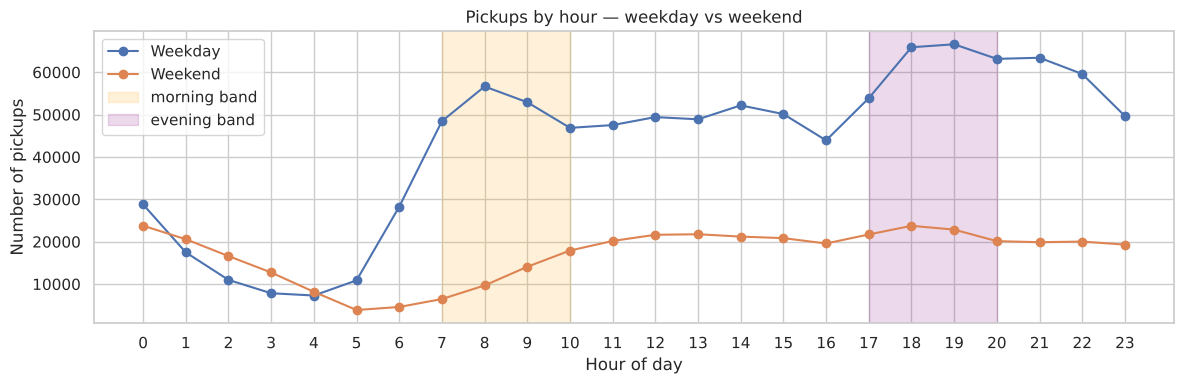

In [10]:
# Hourly counts, split by day type.
hourly = (
    df_clean.groupby(["is_weekend", "pickup_hour"])
    .size()
    .unstack(0)
    .rename(columns={False: "Weekday", True: "Weekend"})
)

fig, ax = plt.subplots(figsize=(12, 4))
hourly.plot(ax=ax, marker="o")
ax.set_xticks(range(24))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Number of pickups")
ax.set_title("Pickups by hour — weekday vs weekend")
ax.axvspan( 7, 10, color="orange", alpha=.15, label="morning band")
ax.axvspan(17, 20, color="purple", alpha=.15, label="evening band")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/pickups_in_a_day.png")
plt.show()

## Justification of morning / evening bands

Morning = 07:00–09:59. The weekday hourly curve shows its sharpest pre-noon maximum here (~08:00). The window captures the entire commute ramp including its shoulders; a wider band (06:00–10:59) would drag in non-peak hours, and a narrower band (08:00–08:59) would discard the shoulders.

Evening = 17:00–19:59. The weekday evening curve has a broad, flatter maximum here (17:00–19:00). The window covers the whole after-work plateau, not just its tip.

The bands are deliberately identical for weekday and weekend. The comparison is only meaningful if we hold time-of-day fixed and let the day-type vary — this isolates the weekday-vs-weekend effect.

### Heatmap version 1: plain grid

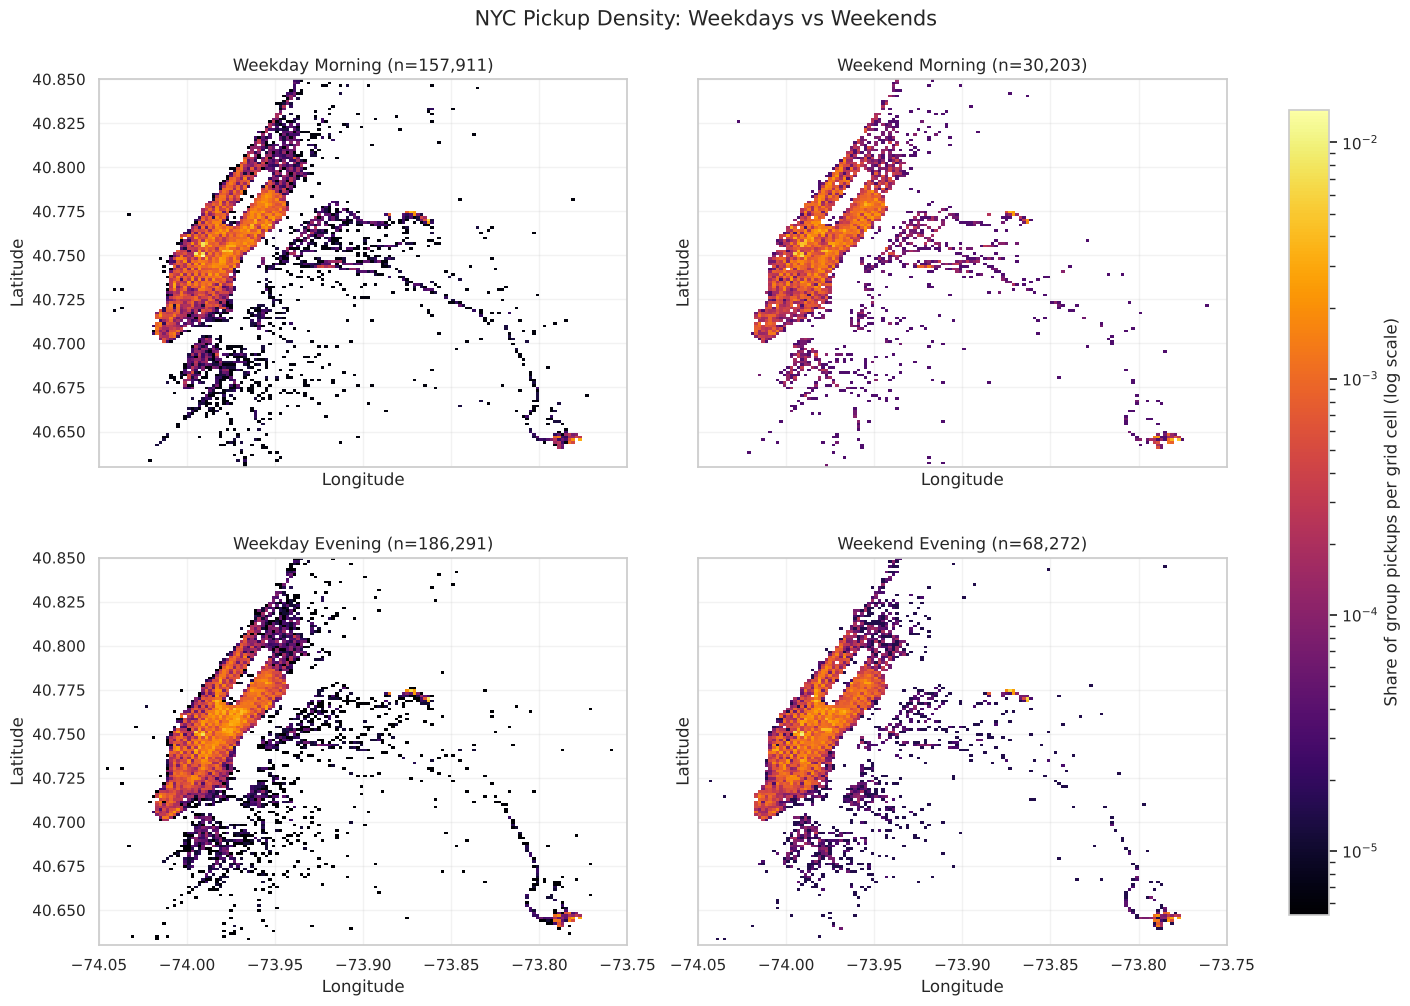

In [11]:
from matplotlib.colors import LogNorm

# 1. Prepare pick-up data

df_plot = df_clean.copy()

# pickup time is in datetime format
df_plot["pickup_datetime"] = pd.to_datetime(
    df_plot["pickup_datetime"], errors="coerce"
)

# Extract pickup hour and identify morning/evening
df_plot["pickup_hour"] = df_plot["pickup_datetime"].dt.hour

df_plot["day_type"] = np.where(
    df_plot["pickup_datetime"].dt.day_of_week >= 5,
    "Weekend",
    "Weekday"
)

df_plot["time_period"] = np.select(
    [
        df_plot["pickup_hour"].between(7, 9),
        df_plot["pickup_hour"].between(17, 19)
    ],
    ["Morning", "Evening"],
    default="other"
)

# Keep only the groups we want to compare
df_plot = df_plot[
    df_plot["time_period"].isin(["Morning", "Evening"])
].copy()

# 2. Define NYC map area
lon_min, lon_max = -74.05, -73.75
lat_min, lat_max = 40.63, 40.85

# Remove missing and out-of-range pickup coordinates
df_plot = df_plot.dropna(
    subset=["pickup_longitude", "pickup_latitude"]
)

df_plot = df_plot[
    df_plot["pickup_longitude"].between(lon_min, lon_max)
    & df_plot["pickup_latitude"].between(lat_min, lat_max)
].copy()

# Use the same grid for every panel
bins = 150

lon_edges = np.linspace(lon_min, lon_max, bins + 1)
lat_edges = np.linspace(lat_min, lat_max, bins + 1)

# 3. Calculate normalized pick-up densities

groups = [
    ("Weekday", "Morning"),
    ("Weekend", "Morning"),
    ("Weekday", "Evening"),
    ("Weekend", "Evening")
]

histograms = {}
all_positive_values = []

for day, period in groups:
    # Select trips belonging to groups
    subset = df_plot[
        (df_plot["day_type"] == day) & (df_plot["time_period"] == period)
    ]

    # Count pickups inside each grid cell
    counts, _, _ = np.histogram2d(
        subset["pickup_longitude"],
        subset["pickup_latitude"],
        bins=[lon_edges, lat_edges]
    )

    # Divide by total trips in this group
    # Each cell now represents a share of group pickups
    density = counts / len(subset) if len(subset) > 0 else counts

    histograms[(day, period)] = (density, len(subset))

    # Store positive values to establish a common colour scale
    positive = density[density > 0]
    if len(positive) > 0:
        all_positive_values.extend(positive)


# Use the same logarithmic colour limits in every panel
vmin = min(all_positive_values)
vmax = max(all_positive_values)

norm = LogNorm(vmin=vmin, vmax=vmax)

# 4. the four heatmaps

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, (day, period) in zip(axes.flat, groups):

    density, number_of_trips = histograms[(day, period)]

    # Hide empty cells so zero values do not enter LogNorm
    density_masked = np.ma.masked_equal(density.T, 0)

    heatmap = ax.pcolormesh(
        lon_edges,
        lat_edges,
        density_masked,
        cmap="inferno",
        norm=norm,
        shading="auto"
    )

    ax.set_title(
        f"{day} {period} (n={number_of_trips:,})"
    )
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_xlim(lon_min, lon_max)
    ax.set_ylim(lat_min, lat_max)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.25)

# One colour bar, outside the plots
fig.colorbar(
    heatmap,
    ax=axes.ravel().tolist(),
    label="Share of group pickups per grid cell (log scale)",
    shrink=0.85,
    pad=0.03
)

fig.suptitle(
    "NYC Pickup Density: Weekdays vs Weekends",
    fontsize=15
)
plt.savefig(f"{FIG_DIR}/nyc_pickup_hitmap.png")
plt.show()

### Heatmap version 2: over a street map

OpenStreetMap tiles unavailable, drawing without a street map: HTTPSConnectionPool(host='tile.openstreetmap.org', port=443): Max retries exceeded with url: /12/1205/1537.png (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))


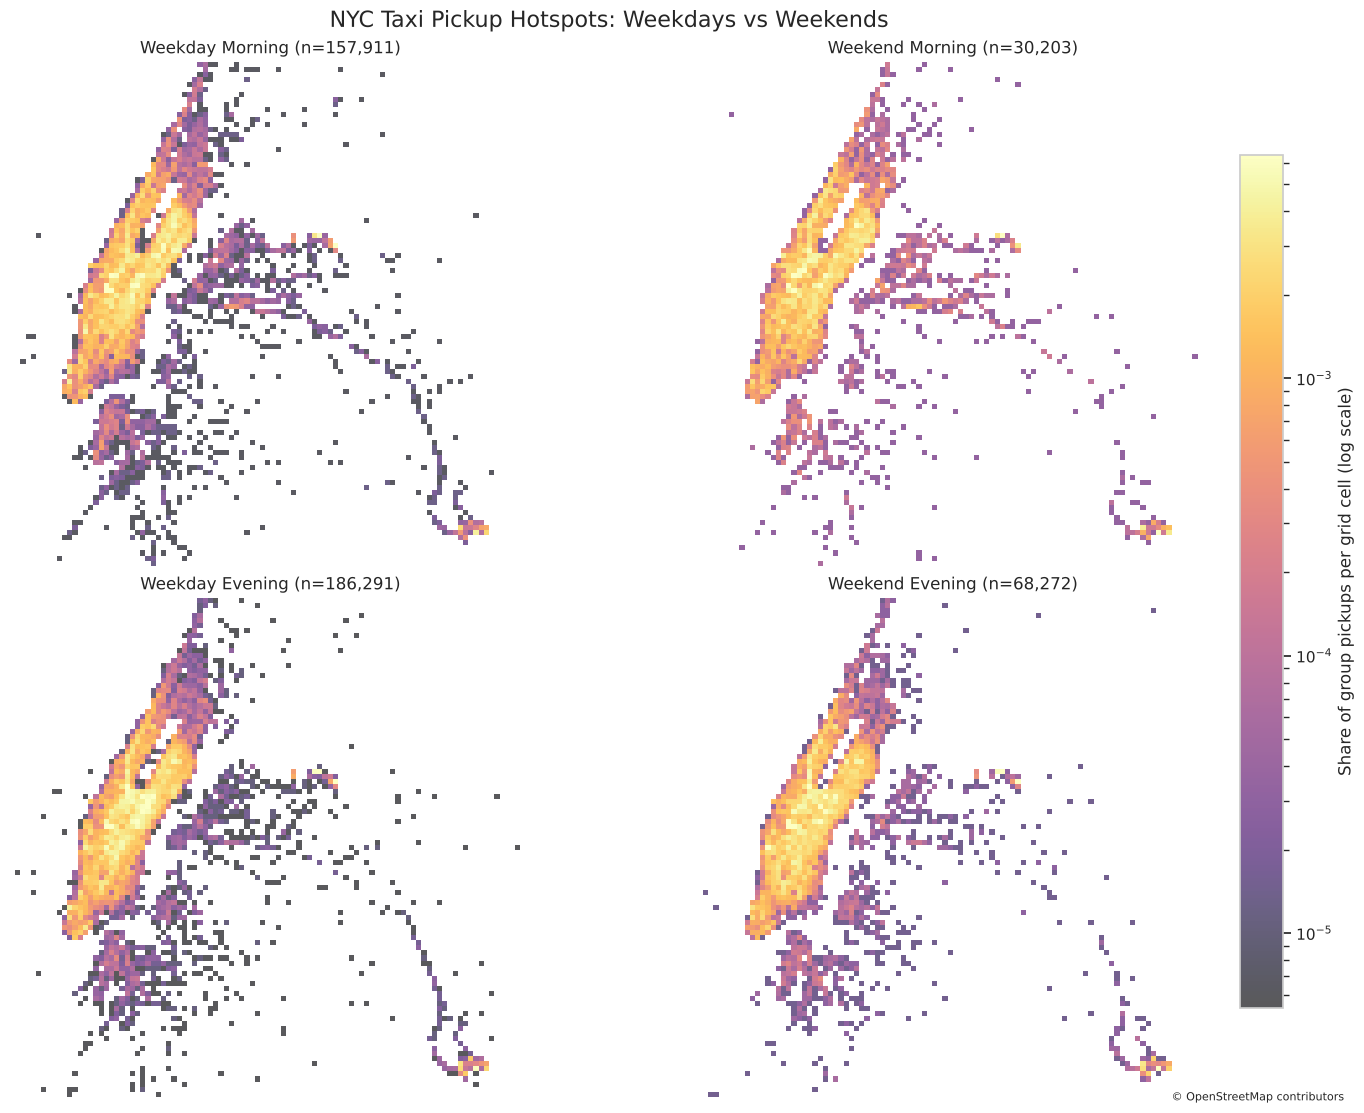

In [12]:
# --------------------------------------------------
# 1. Prepare the data
# --------------------------------------------------

df_map = df_clean.copy()

df_map["pickup_datetime"] = pd.to_datetime(
    df_map["pickup_datetime"], errors="coerce"
)

df_map = df_map.dropna(subset=[
    "pickup_datetime",
    "pickup_longitude",
    "pickup_latitude"
])

# Keep the geographic bounds used in our analysis
lon_min, lon_max = -74.05, -73.75
lat_min, lat_max = 40.63, 40.85

df_map = df_map[
    df_map["pickup_longitude"].between(lon_min, lon_max)
    & df_map["pickup_latitude"].between(lat_min, lat_max)
].copy()

# Classify trips using the pickup date
df_map["day_type"] = np.where(
    df_map["pickup_datetime"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

hour = df_map["pickup_datetime"].dt.hour

df_map["time_period"] = np.select(
    [
        hour.between(7, 9),
        hour.between(17, 19)
    ],
    ["Morning", "Evening"],
    default="Other"
)

groups = [
    ("Weekday", "Morning"),
    ("Weekend", "Morning"),
    ("Weekday", "Evening"),
    ("Weekend", "Evening")
]

df_map = df_map[
    df_map["time_period"].isin(["Morning", "Evening"])
].copy()


# --------------------------------------------------
# 2. Download a static NYC street map
#    No contextily or rasterio required
# --------------------------------------------------

zoom = 12
tile_count = 2 ** zoom
earth_radius = 6378137
world_half = pi * earth_radius


def lon_to_tile(lon):
    return (lon + 180) / 360 * tile_count


def lat_to_tile(lat):
    lat_rad = radians(lat)
    return (
        1 - np.arcsinh(np.tan(lat_rad)) / pi
    ) / 2 * tile_count


# Find which map tiles cover our NYC bounds
x_start = floor(lon_to_tile(lon_min))
x_end = floor(lon_to_tile(lon_max))
y_start = floor(lat_to_tile(lat_max))
y_end = floor(lat_to_tile(lat_min))

# Combine the tiles into one background image
tile_size = 256

map_image = Image.new(
    "RGB",
    (
        (x_end - x_start + 1) * tile_size,
        (y_end - y_start + 1) * tile_size
    )
)

try:
    for x in range(x_start, x_end + 1):
        for y in range(y_start, y_end + 1):

            url = f"https://tile.openstreetmap.org/{zoom}/{x}/{y}.png"

            response = requests.get(
                url,
                headers={"User-Agent": "NYC-Taxi-Analysis/1.0"},
                timeout=20
            )
            response.raise_for_status()

            tile = Image.open(BytesIO(response.content)).convert("RGB")

            map_image.paste(
                tile,
                (
                    (x - x_start) * tile_size,
                    (y - y_start) * tile_size
                )
            )
    basemap_ok = True
except Exception as err:
    basemap_ok = False
    print("OpenStreetMap tiles unavailable, drawing without a street map:", err)

# Calculate the geographic extent of the background image
tile_width = 2 * world_half / tile_count

map_left = -world_half + x_start * tile_width
map_right = -world_half + (x_end + 1) * tile_width
map_top = world_half - y_start * tile_width
map_bottom = world_half - (y_end + 1) * tile_width

map_extent = [
    map_left, map_right, map_bottom, map_top
]


# --------------------------------------------------
# 3. Convert pickup coordinates to map coordinates
# --------------------------------------------------

def to_web_mercator(lon, lat):
    x = earth_radius * np.radians(lon)
    y = earth_radius * np.log(
        np.tan(np.pi / 4 + np.radians(lat) / 2)
    )
    return x, y


df_map["x"], df_map["y"] = to_web_mercator(
    df_map["pickup_longitude"].to_numpy(),
    df_map["pickup_latitude"].to_numpy()
)

x_min, y_min = to_web_mercator(lon_min, lat_min)
x_max, y_max = to_web_mercator(lon_max, lat_max)


# --------------------------------------------------
# 4. Calculate the same grid for all four groups
# --------------------------------------------------

number_of_bins = 100

x_edges = np.linspace(x_min, x_max, number_of_bins + 1)
y_edges = np.linspace(y_min, y_max, number_of_bins + 1)

heatmaps = {}
positive_values = []

for day, period in groups:

    subset = df_map[
        (df_map["day_type"] == day)
        & (df_map["time_period"] == period)
    ]

    if subset.empty:
        raise ValueError(f"No trips found for {day} {period}.")

    # Count pickups in each grid cell
    counts, _, _ = np.histogram2d(
        subset["x"],
        subset["y"],
        bins=[x_edges, y_edges]
    )

    # Normalise so groups with different trip totals
    # can be compared by spatial distribution
    density = counts / len(subset)

    heatmaps[(day, period)] = (density, len(subset))

    positive_values.extend(
        density[density > 0].tolist()
    )

# One shared logarithmic scale for all four panels
vmin = np.percentile(positive_values, 5)
vmax = np.percentile(positive_values, 99.5)

if vmax <= vmin:
    vmax = vmin * 1.01

colour_scale = LogNorm(vmin=vmin, vmax=vmax)


# --------------------------------------------------
# 5. Draw the static heatmaps
# --------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 11),
    constrained_layout=True
)

for ax, (day, period) in zip(axes.flat, groups):

    density, trip_count = heatmaps[(day, period)]

    # Draw the labelled street map first
    if basemap_ok: ax.imshow(
        map_image,
        extent=map_extent,
        origin="upper",
        zorder=0
    )

    # Overlay the pickup-density grid
    density = np.ma.masked_less_equal(density.T, 0)

    heatmap = ax.pcolormesh(
        x_edges,
        y_edges,
        density,
        cmap="inferno",
        norm=colour_scale,
        alpha=0.65,
        shading="auto",
        zorder=1
    )

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect("equal")
    ax.set_title(f"{day} {period} (n={trip_count:,})")
    ax.set_axis_off()

# One colour bar for the whole figure
fig.colorbar(
    heatmap,
    ax=axes.ravel().tolist(),
    label="Share of group pickups per grid cell (log scale)",
    shrink=0.82,
    pad=0.02
)

fig.suptitle(
    "NYC Taxi Pickup Hotspots: Weekdays vs Weekends",
    fontsize=16
)

# Required attribution for the street-map tiles
fig.text(
    0.99, 0.005,
    "© OpenStreetMap contributors",
    ha="right",
    fontsize=8
)

# Save a high-resolution static figure
plt.savefig(
    f"{FIG_DIR}/nyc_static_pickup_heatmaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Findings and interpretation

The heatmaps show the geographic distribution of taxi pickups during weekday and weekend mornings (07:00–09:59) and evenings (17:00–19:59). The same geographic grid and colour scale are used across all four panels to make spatial comparisons easier.

The brightest areas indicate locations with the highest relative concentration of pickups within each group. Comparing weekdays with weekends can reveal whether pickup activity is concentrated in different areas or distributed differently across the city. Comparing morning and evening periods can also reveal changes in the locations where pickups are concentrated.

These patterns should be interpreted in terms of the relative share of pickups because the heatmaps are normalised by the total number of pickups in each group.

## 4.2 Hotspots

If you were a taxi driver wanting to plan your evenings so that you could get the most trips, you would want to know where the popular areas are. 
Looking at the time periods 23:00 on a Friday evening to 02:00 on a Saturday morning, and between 17:00 and 20:00 on a Thursday, find hotspot locations (areas where there are a large number of trips happening).
If you were to use k-means, you would define the number of clusters. However, here the number of clusters is not at all clear. DBSCAN (available in sklearn) determines this for you, and works well on spatial data.
DBSCAN has two configurable parameters: ϵ the maximum distance between any two points, and the minimum number of samples to determine a cluster. 
Your hotspot location might be defined as at least 15 pickups in that location in an hour, and locations might be required to be within 50 or 100 metres from each other (motivate your choice of parameters). Using DBSCAN, identify clusters and plot these on a map. How many clusters
did you find? [8 marks]

In [13]:
# Load data

# 1. Start from the cleaned trips (Question 1)
hs = df_clean.copy()

# 2. Keep rows with valid pickup information
hs = hs.dropna(subset=[
    "pickup_datetime",
    "pickup_longitude",
    "pickup_latitude"
]).copy()

# 3. Keep pickups within our NYC map area
hs = hs[
    hs["pickup_longitude"].between(-74.05, -73.75)
    & hs["pickup_latitude"].between(40.63, 40.85)
].copy()

# 4. Extract day and hour
hs["day"] = hs["pickup_datetime"].dt.dayofweek
hs["hour"] = hs["pickup_datetime"].dt.hour

# 5. Select the two requested periods
friday_night = (
    (hs["day"] == 4) & (hs["hour"] == 23)
) | (
    (hs["day"] == 5) & (hs["hour"].between(0, 1))
)

thursday_evening = (
    (hs["day"] == 3) & (hs["hour"].between(17, 19))
)

hs["period"] = np.select(
    [friday_night, thursday_evening],
    ["Friday night", "Thursday evening"],
    default="Other"
)

hs = hs[hs["period"] != "Other"].copy()

print("Selected pickups:")
print(hs["period"].value_counts())
print("Total selected pickups:", len(hs))

Selected pickups:
period
Thursday evening    37891
Friday night        34478
Name: count, dtype: int64
Total selected pickups: 72369


In [14]:
# Find the clusters

# DBSCAN settings
earth_radius_km = 6371.0088
epsilon = 0.15 / earth_radius_km  # 150 metres in radians
min_pickups = 15

# Store the results
results = []

# Analyse each period, one hour at a time
for period in ["Friday night", "Thursday evening"]:

    period_data = hs[hs["period"] == period]

    for hour_start, group in period_data.groupby(
        period_data["pickup_datetime"].dt.floor("h")
    ):

        # DBSCAN requires [latitude, longitude] in radians
        coords = np.radians(
            group[["pickup_latitude", "pickup_longitude"]].to_numpy()
        )

        # Find clusters
        db = DBSCAN(
            eps=epsilon,
            min_samples=min_pickups,
            metric="haversine",
            algorithm="ball_tree"
        )

        labels = db.fit_predict(coords)

        # Count the clusters, ignoring noise labelled -1
        group = group.copy()
        group["cluster"] = labels

        for cluster_id, cluster in group[
            group["cluster"] != -1
        ].groupby("cluster"):

            results.append({
                "period": period,
                "hour": hour_start,
                "cluster": cluster_id,
                "latitude": cluster["pickup_latitude"].mean(),
                "longitude": cluster["pickup_longitude"].mean(),
                "pickups": len(cluster)
            })


# Put all detected clusters into a DataFrame
columns = [
    "period", "hour", "cluster",
    "latitude", "longitude", "pickups"
]

clusters = pd.DataFrame(results, columns=columns)

if clusters.empty:
    print("No clusters were found.")
    print("Try increasing epsilon from 100 metres to 150 metres.")
else:
    print("Clusters found:")
    print(clusters.groupby("period").size())

    print("\nTotal hourly cluster detections:", len(clusters))

    print("\nLargest clusters:")
    print(
        clusters.sort_values("pickups", ascending=False)
        .head(10)
        .to_string(index=False)
    )

Clusters found:
period
Friday night        4
Thursday evening    2
dtype: int64

Total hourly cluster detections: 6

Largest clusters:
          period                hour  cluster  latitude  longitude  pickups
Thursday evening 2016-01-28 19:00:00        0    40.770    -73.863       17
    Friday night 2016-01-30 01:00:00        0    40.719    -73.990       16
    Friday night 2016-04-16 01:00:00        0    40.740    -74.006       16
    Friday night 2016-03-26 01:00:00        0    40.722    -73.987       15
    Friday night 2016-06-11 01:00:00        0    40.741    -74.006       15
Thursday evening 2016-01-07 18:00:00        0    40.749    -73.992       15


OpenStreetMap tiles unavailable, drawing without a street map: HTTPSConnectionPool(host='tile.openstreetmap.org', port=443): Max retries exceeded with url: /12/1205/1537.png (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))


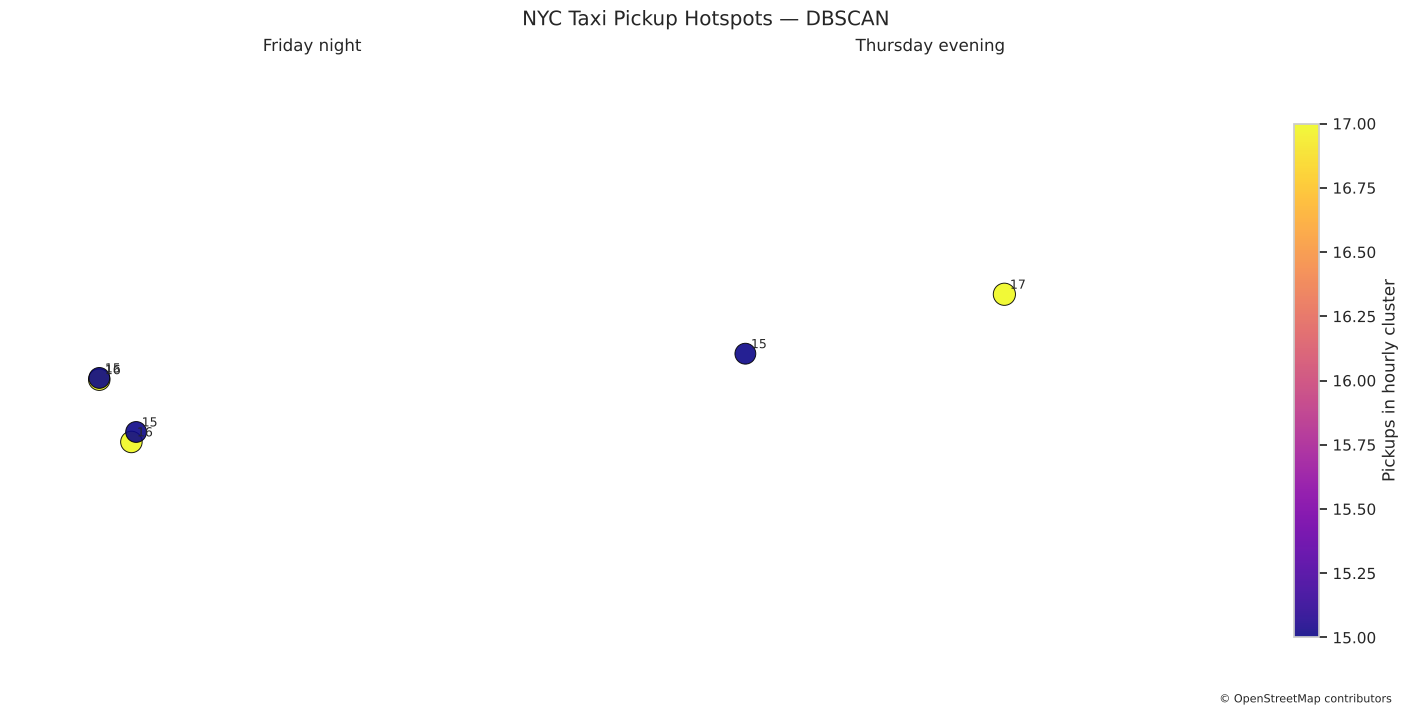

In [15]:
# 1. Map area around NYC
lon_min, lon_max = -74.05, -73.75
lat_min, lat_max = 40.63, 40.85

zoom = 12
tile_count = 2 ** zoom
tile_size = 256
earth_radius = 6378137
world_half = pi * earth_radius

# 2. Convert longitude and latitude to map tile numbers
def lon_to_tile(lon):
    return (lon + 180) / 360 * tile_count

def lat_to_tile(lat):
    return (
        1 - np.arcsinh(np.tan(np.radians(lat))) / pi
    ) / 2 * tile_count

x_start = floor(lon_to_tile(lon_min))
x_end = floor(lon_to_tile(lon_max))
y_start = floor(lat_to_tile(lat_max))
y_end = floor(lat_to_tile(lat_min))

# 3. Download only the tiles needed for this map
map_image = Image.new(
    "RGB",
    (
        (x_end - x_start + 1) * tile_size,
        (y_end - y_start + 1) * tile_size
    )
)

try:
    for x in range(x_start, x_end + 1):
        for y in range(y_start, y_end + 1):
            url = f"https://tile.openstreetmap.org/{zoom}/{x}/{y}.png"

            response = requests.get(
                url,
                headers={"User-Agent": "NYCTaxiCoursework/1.0"},
                timeout=20
            )
            response.raise_for_status()

            tile = Image.open(
                BytesIO(response.content)
            ).convert("RGB")

            map_image.paste(
                tile,
                (
                    (x - x_start) * tile_size,
                    (y - y_start) * tile_size
                )
            )
    basemap_ok = True
except Exception as err:
    basemap_ok = False
    print("OpenStreetMap tiles unavailable, drawing without a street map:", err)

# 4. Calculate the geographic extent of the downloaded map
tile_width = 2 * world_half / tile_count

map_extent = [
    -world_half + x_start * tile_width,
    -world_half + (x_end + 1) * tile_width,
    world_half - (y_end + 1) * tile_width,
    world_half - y_start * tile_width
]

# 5. Convert hotspot coordinates to the same map projection
def to_web_mercator(lon, lat):
    x = earth_radius * np.radians(lon)
    y = earth_radius * np.log(
        np.tan(np.pi / 4 + np.radians(lat) / 2)
    )
    return x, y

x_min, y_min = to_web_mercator(lon_min, lat_min)
x_max, y_max = to_web_mercator(lon_max, lat_max)

# 6. Plot the two time periods on street maps
fig, axes = plt.subplots(
    1, 2, figsize=(14, 7),
    constrained_layout=True
)

for ax, period in zip(
    axes, ["Friday night", "Thursday evening"]
):
    # Street map background
    if basemap_ok: ax.imshow(
        map_image,
        extent=map_extent,
        origin="upper"
    )

    data = clusters[clusters["period"] == period].copy()

    if not data.empty:
        data["x"], data["y"] = to_web_mercator(
            data["longitude"].to_numpy(),
            data["latitude"].to_numpy()
        )

        points = ax.scatter(
            data["x"],
            data["y"],
            s=data["pickups"] * 15,
            c=data["pickups"],
            cmap="plasma",
            edgecolor="black",
            linewidth=0.7,
            alpha=0.9
        )

        for _, row in data.iterrows():
            ax.annotate(
                str(row["pickups"]),
                (row["x"], row["y"]),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=9
            )

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_title(period)
    ax.set_axis_off()

if not clusters.empty:
    fig.colorbar(
        points,
        ax=axes,
        label="Pickups in hourly cluster",
        shrink=0.8
    )

fig.suptitle("NYC Taxi Pickup Hotspots — DBSCAN")
fig.text(
    0.99, 0.005,
    "© OpenStreetMap contributors",
    ha="right", fontsize=8
)

plt.savefig(
    f"{FIG_DIR}/nyc_dbscan_street_map.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Question 5: Airports

#### Trips from ESB(Empire State Building) to airports

In [16]:
# ESB, JFK and EWR are defined in the setup cell as (latitude, longitude)

# Calculate distance from each pickup to ESB
df_clean["esb_pickup_km"] = haversine_np(
    df_clean["pickup_longitude"],
    df_clean["pickup_latitude"],
    ESB[1], ESB[0]
)

# Calculate distance from each dropoff to JFK
df_clean["jfk_dropoff_km"] = haversine_np(
    df_clean["dropoff_longitude"],
    df_clean["dropoff_latitude"],
    JFK[1], JFK[0]
)

# Calculate distance from each dropoff to Newark
df_clean["ewr_dropoff_km"] = haversine_np(
    df_clean["dropoff_longitude"],
    df_clean["dropoff_latitude"],
    EWR[1], EWR[0]
)

# Choose our starting radii
ESB_RADIUS = 0.5
AIRPORT_RADIUS = 2.0

# Trips starting near Empire State Building
from_esb = df_clean["esb_pickup_km"] <= ESB_RADIUS

# Find trips going from ESB to each airport
jfk_trips = df_clean[
    from_esb &
    (df_clean["jfk_dropoff_km"] <= AIRPORT_RADIUS)
].copy()

ewr_trips = df_clean[
    from_esb &
    (df_clean["ewr_dropoff_km"] <= AIRPORT_RADIUS)
].copy()

# Convert travel time from seconds to minutes
jfk_trips["travel_minutes"] = jfk_trips["trip_duration"] / 60
ewr_trips["travel_minutes"] = ewr_trips["trip_duration"] / 60

# Display results
print("ESB to JFK:")
print("Number of trips:", len(jfk_trips))
print("Average minutes:", round(jfk_trips["travel_minutes"].mean(), 2))

print("\nESB to Newark:")
print("Number of trips:", len(ewr_trips))
print("Average minutes:", round(ewr_trips["travel_minutes"].mean(), 2))

ESB to JFK:
Number of trips: 863
Average minutes: 49.44

ESB to Newark:
Number of trips: 236
Average minutes: 36.28


#### Test different radii

In [17]:
 

def test_radii(esb_radius, airport_radius):
    for airport, col in [
        ("JFK", "jfk_dropoff_km"),
        ("Newark", "ewr_dropoff_km")
    ]:
        trips = df_clean[
            (df_clean["esb_pickup_km"] <= esb_radius) &
            (df_clean[col] <= airport_radius)
        ]

        avg = trips["trip_duration"].mean() / 60

        print(
            f"{airport}: {len(trips)} trips, "
            f"average = {avg:.2f} minutes"
        )

# Test different ESB radii
print("TEST 1: Changing ESB radius")
for radius in [0.3, 0.5, 0.8]:
    print(f"\nESB radius = {radius} km")
    test_radii(radius, 2.0)

# Test different airport radii
print("\nTEST 2: Changing airport radius")
for radius in [1.0, 2.0, 3.0]:
    print(f"\nAirport radius = {radius} km")
    test_radii(0.5, radius)

TEST 1: Changing ESB radius

ESB radius = 0.3 km
JFK: 365 trips, average = 49.26 minutes
Newark: 99 trips, average = 36.39 minutes

ESB radius = 0.5 km
JFK: 863 trips, average = 49.44 minutes
Newark: 236 trips, average = 36.28 minutes

ESB radius = 0.8 km
JFK: 2006 trips, average = 49.67 minutes
Newark: 547 trips, average = 37.11 minutes

TEST 2: Changing airport radius

Airport radius = 1.0 km
JFK: 541 trips, average = 48.79 minutes
Newark: 230 trips, average = 36.43 minutes

Airport radius = 2.0 km
JFK: 863 trips, average = 49.44 minutes
Newark: 236 trips, average = 36.28 minutes

Airport radius = 3.0 km
JFK: 917 trips, average = 49.38 minutes
Newark: 238 trips, average = 36.26 minutes


#### Average travel time and number of trips by hour

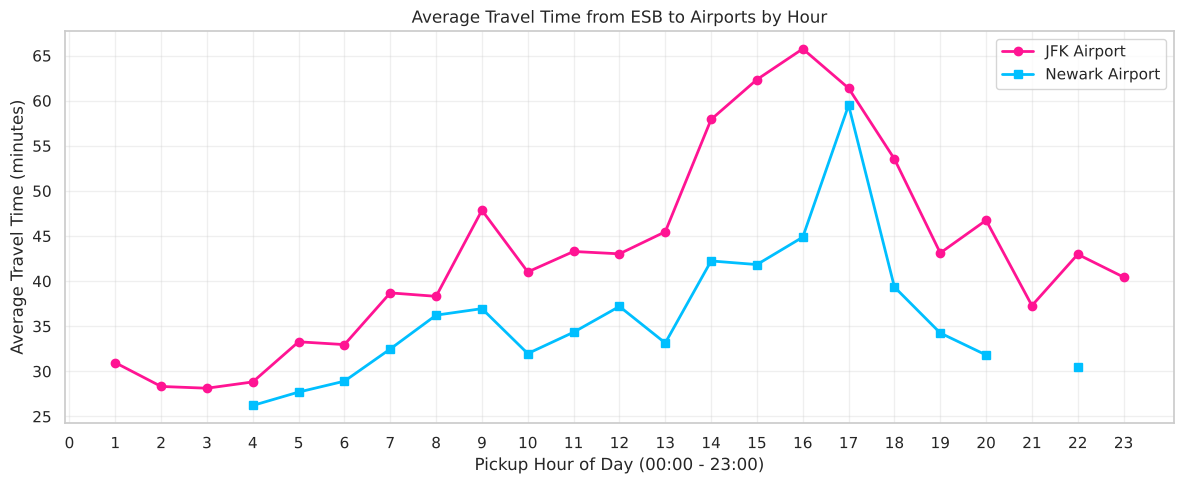

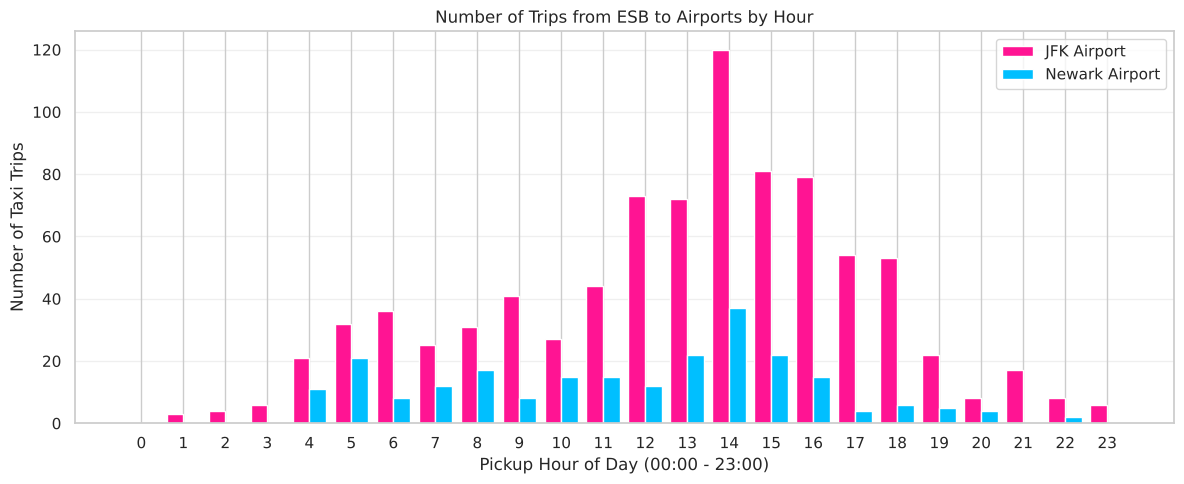

JFK hourly results:


,mean,count
pickup_hour,,
0,NaN,0.000
1,30.960,3.000
2,28.320,4.000
3,28.130,6.000
4,28.830,21.000
5,33.280,32.000
6,32.960,36.000
7,38.700,25.000
8,38.310,31.000


Newark hourly results:


,mean,count
pickup_hour,,
0,NaN,0.000
1,NaN,0.000
2,NaN,0.000
3,NaN,0.000
4,26.220,11.000
5,27.700,21.000
6,28.910,8.000
7,32.480,12.000
8,36.230,17.000


In [18]:
jfk_hourly = jfk_trips.groupby("pickup_hour")["travel_minutes"].agg(
    ["mean", "count"]
).reindex(range(24))

ewr_hourly = ewr_trips.groupby("pickup_hour")["travel_minutes"].agg(
    ["mean", "count"]
).reindex(range(24))

jfk_hourly["count"] = jfk_hourly["count"].fillna(0)
ewr_hourly["count"] = ewr_hourly["count"].fillna(0)

hours = np.arange(24)

plt.figure(figsize=(12, 5))

plt.plot(
    hours, jfk_hourly["mean"],
    marker="o", linewidth=2, label="JFK Airport", color='#FF1493'
)
plt.plot(
    hours, ewr_hourly["mean"],
    marker="s", linewidth=2, label="Newark Airport", color='#00BFFF'
)

plt.title("Average Travel Time from ESB to Airports by Hour")
plt.xlabel("Pickup Hour of Day (00:00 - 23:00)")
plt.ylabel("Average Travel Time (minutes)")
plt.xticks(hours)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/travel_time_by_hour.png", dpi=150)
plt.show()

plt.figure(figsize=(12, 5))

width = 0.4

plt.bar(
    hours - width / 2,
    jfk_hourly["count"],
    width=width, label="JFK Airport", color='#FF1493'
)

plt.bar(
    hours + width / 2,
    ewr_hourly["count"],
    width=width, label="Newark Airport", color='#00BFFF'
)

plt.title("Number of Trips from ESB to Airports by Hour")
plt.xlabel("Pickup Hour of Day (00:00 - 23:00)")
plt.ylabel("Number of Taxi Trips")
plt.xticks(hours)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/trips_by_hour.png", dpi=150)
plt.show()

# Display hourly data
print("JFK hourly results:")
display(jfk_hourly.round(2))

print("Newark hourly results:")
display(ewr_hourly.round(2))

#### Airport Flags

In [19]:
# pickup distances to both airports
df_clean["jfk_pickup_km"] = haversine_np(
    df_clean["pickup_longitude"],
    df_clean["pickup_latitude"],
    JFK[1], JFK[0]
)

df_clean["ewr_pickup_km"] = haversine_np(
    df_clean["pickup_longitude"],
    df_clean["pickup_latitude"],
    EWR[1], EWR[0]
)

airport_flags = pd.DataFrame({
    "id": df_clean["id"],
    "near_jfk_pickup": df_clean["jfk_pickup_km"] <= 2.0,
    "near_jfk_dropoff": df_clean["jfk_dropoff_km"] <= 2.0,
    "near_ewr_pickup": df_clean["ewr_pickup_km"] <= 2.0,
    "near_ewr_dropoff": df_clean["ewr_dropoff_km"] <= 2.0
})

# True if a trip starts OR ends near either airport
flag_columns = [
    "near_jfk_pickup",
    "near_jfk_dropoff",
    "near_ewr_pickup",
    "near_ewr_dropoff"
]

airport_flags["airport_trip"] = (
    airport_flags[flag_columns].any(axis=1)
)

#airport_flags.to_csv("airport_flags.csv", index=False)

# Verify the output
print("Total trips:", len(airport_flags))
print("Airport-related trips:",
      airport_flags["airport_trip"].sum())

print("Duplicate IDs:", airport_flags["id"].duplicated().sum())

display(airport_flags.head())

Total trips: 1442031
Airport-related trips: 43680


Duplicate IDs: 0


,id,near_jfk_pickup,near_jfk_dropoff,near_ewr_pickup,near_ewr_dropoff,airport_trip
0,id2875421,False,False,False,False,False
1,id2377394,False,False,False,False,False
2,id3858529,False,False,False,False,False
3,id3504673,False,False,False,False,False
4,id2181028,False,False,False,False,False


# Question 6: Dimensionality reduction

In [20]:
plt.style.use("default")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8})
WEEKDAY_C, WEEKEND_C, GREY_C = "#2a78d6", "#eb6834", "#c9c8c2"
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
DIST_CMAP = ListedColormap(plt.get_cmap("Blues")(np.linspace(0.3, 1.0, 256)))

def savefig(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight")
    plt.show()

Question 6 uses the airport flags from Question 5 (pickup or drop-off within 2 km of JFK or Newark).

In [21]:
AIRPORT_RADIUS_KM = AIRPORT_RADIUS
df_clean = df_clean.merge(airport_flags, on="id", how="left")
print(f"Cleaned trips: {len(df_clean):,}  |  airport trips: {df_clean.airport_trip.sum():,}")

Cleaned trips: 1,442,031  |  airport trips: 43,680


## 6.1 Sample and feature matrix

In [22]:
sample = df_clean.sample(n=20_000, random_state=SEED).reset_index(drop=True)

features = pd.DataFrame({
    "pickup_latitude": sample.pickup_latitude,
    "pickup_longitude": sample.pickup_longitude,
    "dropoff_latitude": sample.dropoff_latitude,
    "dropoff_longitude": sample.dropoff_longitude,
    "log_distance_km": np.log1p(sample.distance_km),
    "log_trip_duration": np.log1p(sample.trip_duration),
    "speed_kmh": sample.speed_kmh,
    "hour_sin": np.sin(2 * np.pi * sample.pickup_hour / 24),
    "hour_cos": np.cos(2 * np.pi * sample.pickup_hour / 24),
    "dow_sin": np.sin(2 * np.pi * sample.pickup_dow / 7),
    "dow_cos": np.cos(2 * np.pi * sample.pickup_dow / 7),
})
X = StandardScaler().fit_transform(features)
FEATURES = list(features.columns)

skew = pd.DataFrame({"raw": [sample.distance_km.skew(), sample.trip_duration.skew(), sample.speed_kmh.skew()],
                     "log1p": [features.log_distance_km.skew(), features.log_trip_duration.skew(), np.log1p(sample.speed_kmh).skew()]},
                    index=["distance_km", "trip_duration", "speed_kmh"])
print("Skewness before/after log1p:\n", skew.round(2))
print(f"\nSample: {len(sample):,} trips, {sample.airport_trip.sum()} airport trips ({sample.airport_trip.mean():.1%}), "
      f"{sample.is_weekend.mean():.1%} weekend")

pd.DataFrame(X, columns=FEATURES).assign(id=sample.id.values)[["id"] + FEATURES].to_csv("q6_feature_matrix.csv", index=False)
sample[["id"]].to_csv("q6_sample_ids.csv", index=False)

Skewness before/after log1p:
                 raw  log1p
distance_km   2.790  0.960
trip_duration 2.460 -0.200
speed_kmh     1.460 -0.090

Sample: 20,000 trips, 598 airport trips (3.0%), 28.5% weekend


## 6.2 PCA

Components for 90% variance: 8 (cumulative 0.900)
             PC1   PC2   PC3   PC4   PC5   PC6   PC7   PC8   PC9  PC10  PC11
explained  0.227 0.139 0.118 0.101 0.092 0.086 0.074 0.064 0.050 0.047 0.002
cumulative 0.227 0.366 0.484 0.585 0.677 0.762 0.836 0.900 0.950 0.998 1.000


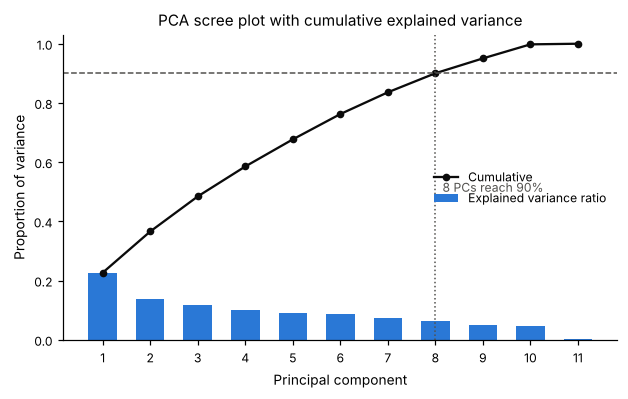

In [23]:
t0 = time.perf_counter()
pca = PCA(random_state=SEED).fit(X)
Z_pca_full = pca.transform(X)
RUNTIME = {"PCA": time.perf_counter() - t0}

evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
K90 = int(np.searchsorted(cum, 0.90) + 1)
Z_pca = Z_pca_full[:, :2]
Z_pca90 = Z_pca_full[:, :K90]
print(f"Components for 90% variance: {K90} (cumulative {cum[K90 - 1]:.3f})")
print(pd.DataFrame({"explained": evr, "cumulative": cum}, index=[f"PC{i + 1}" for i in range(len(evr))]).round(3).T)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
idx = np.arange(1, len(evr) + 1)
ax.bar(idx, evr, color=WEEKDAY_C, width=0.6, label="Explained variance ratio")
ax.plot(idx, cum, color="#0b0b0b", marker="o", ms=4, lw=1.5, label="Cumulative")
ax.axhline(0.9, color="#52514e", ls="--", lw=1)
ax.axvline(K90, color="#52514e", ls=":", lw=1)
ax.text(K90 + 0.15, 0.5, f"{K90} PCs reach 90%", fontsize=8, color="#52514e")
ax.set_xticks(idx)
ax.set_xlabel("Principal component")
ax.set_ylabel("Proportion of variance")
ax.set_ylim(0, 1.03)
ax.legend(frameon=False, fontsize=8, loc="center right")
ax.set_title("PCA scree plot with cumulative explained variance")
savefig(fig, "q6_2_scree")

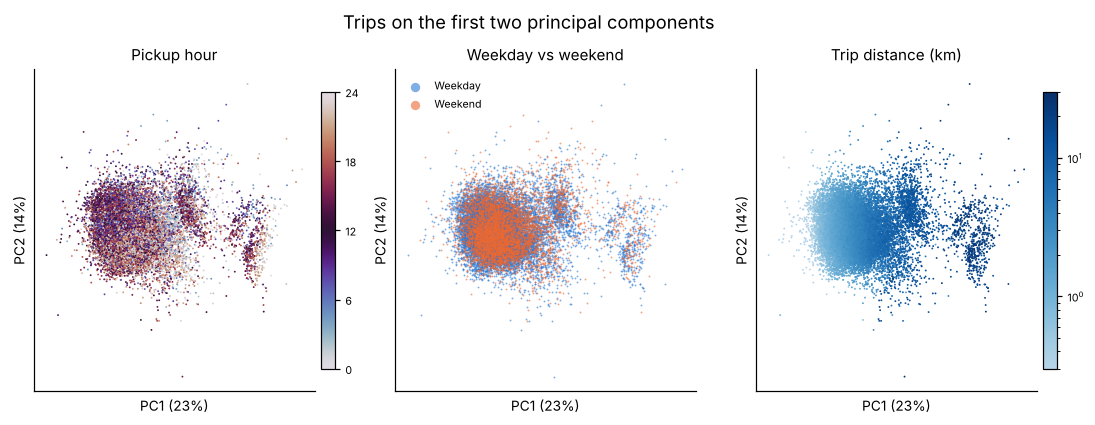

In [24]:
def plot_embedding(ax, Z, colour, title=None, s=1.5, legend=True):
    if colour == "hour":
        sc = ax.scatter(Z[:, 0], Z[:, 1], c=sample.pickup_hour, cmap="twilight", vmin=0, vmax=24, s=s, lw=0, rasterized=True)
    elif colour == "weekend":
        wk = sample.is_weekend.values
        ax.scatter(Z[~wk, 0], Z[~wk, 1], c=WEEKDAY_C, s=s, lw=0, alpha=0.6, rasterized=True, label="Weekday")
        ax.scatter(Z[wk, 0], Z[wk, 1], c=WEEKEND_C, s=s, lw=0, alpha=0.6, rasterized=True, label="Weekend")
        sc = None
        if legend:
            ax.legend(frameon=False, fontsize=7, markerscale=5, loc="best")
    elif colour == "distance":
        order = np.argsort(sample.distance_km.values)
        sc = ax.scatter(Z[order, 0], Z[order, 1], c=sample.distance_km.values[order], cmap=DIST_CMAP,
                        norm=LogNorm(vmin=0.3, vmax=30), s=s, lw=0, rasterized=True)
    elif colour == "airport":
        ap = sample.airport_trip.values
        ax.scatter(Z[~ap, 0], Z[~ap, 1], c=GREY_C, s=s, lw=0, rasterized=True, label="Other trips")
        ax.scatter(Z[ap, 0], Z[ap, 1], c=WEEKEND_C, s=s * 2, lw=0, rasterized=True, label="Airport trips")
        sc = None
        if legend:
            ax.legend(frameon=False, fontsize=7, markerscale=4, loc="best")
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title)
    return sc

COLOURINGS = {"hour": "Pickup hour", "weekend": "Weekday vs weekend", "distance": "Trip distance (km)"}

def add_colourbar(fig, ax, sc, colour):
    if sc is None:
        return
    cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.02)
    if colour == "hour":
        cb.set_ticks([0, 6, 12, 18, 24])
    cb.ax.tick_params(labelsize=7)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (key, label) in zip(axes, COLOURINGS.items()):
    sc = plot_embedding(ax, Z_pca, key, label)
    add_colourbar(fig, ax, sc, key)
    ax.set_xlabel(f"PC1 ({evr[0]:.0%})")
    ax.set_ylabel(f"PC2 ({evr[1]:.0%})")
fig.suptitle("Trips on the first two principal components", y=1.02)
savefig(fig, "q6_2_pca_pc1_pc2")

                     PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8
pickup_latitude   -0.240  0.540 -0.130 -0.180 -0.060 -0.080 -0.280 -0.190
pickup_longitude   0.360  0.200 -0.090 -0.060  0.090 -0.020  0.770 -0.070
dropoff_latitude  -0.150  0.610 -0.020 -0.210 -0.030 -0.050  0.050 -0.330
dropoff_longitude  0.290  0.410  0.020 -0.030 -0.070  0.090 -0.210  0.810
log_distance_km    0.600  0.010 -0.100 -0.050 -0.040 -0.060 -0.200 -0.220
log_trip_duration  0.440 -0.150 -0.440 -0.220 -0.050 -0.190 -0.330 -0.190
speed_kmh          0.390  0.250  0.440  0.230  0.010  0.180  0.060 -0.160
hour_sin           0.020  0.130 -0.140  0.800 -0.250  0.220 -0.170 -0.200
hour_cos           0.110 -0.110  0.640 -0.300 -0.010  0.280 -0.260 -0.210
dow_sin           -0.030  0.010 -0.360 -0.140  0.410  0.820 -0.030 -0.040
dow_cos            0.030  0.090  0.100  0.260  0.870 -0.330 -0.180 -0.020


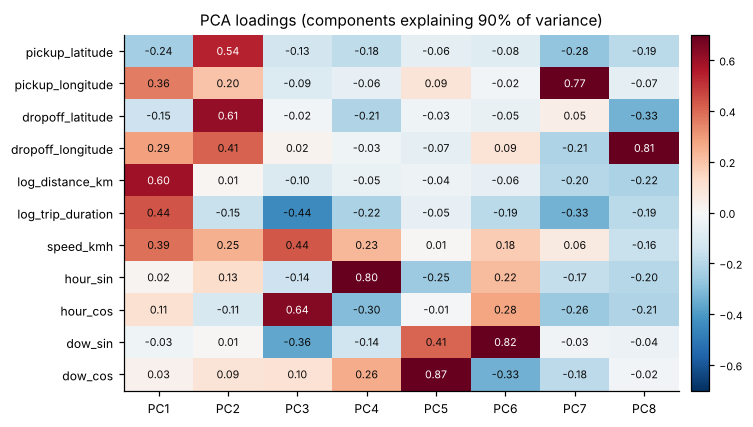

In [25]:
loadings = pd.DataFrame(pca.components_[:K90].T, index=FEATURES, columns=[f"PC{i + 1}" for i in range(K90)])
print(loadings.round(2))

fig, ax = plt.subplots(figsize=(1.0 + 0.75 * K90, 4.2))
im = ax.imshow(loadings.values, cmap="RdBu_r", vmin=-0.7, vmax=0.7, aspect="auto")
ax.set_xticks(range(K90))
ax.set_xticklabels(loadings.columns)
ax.set_yticks(range(len(FEATURES)))
ax.set_yticklabels(FEATURES)
for i in range(len(FEATURES)):
    for j in range(K90):
        v = loadings.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.45 else "#0b0b0b")
fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02).ax.tick_params(labelsize=7)
ax.set_title("PCA loadings (components explaining 90% of variance)")
savefig(fig, "q6_2_loadings")

## 6.3 t-SNE

In [26]:
def run_tsne(perplexity, seed=SEED, init="pca"):
    t0 = time.perf_counter()
    Z = TSNE(n_components=2, perplexity=perplexity, init=init, learning_rate="auto", random_state=seed).fit_transform(X)
    return Z, time.perf_counter() - t0

PERPLEXITIES = [5, 30, 100]
TSNE_EMB = {}
for p in PERPLEXITIES:
    TSNE_EMB[p], RUNTIME[f"t-SNE perplexity={p}"] = run_tsne(p)
    print(f"t-SNE perplexity={p}: {RUNTIME[f't-SNE perplexity={p}']:.1f} s")

t-SNE perplexity=5: 85.1 s


t-SNE perplexity=30: 100.5 s


t-SNE perplexity=100: 159.7 s


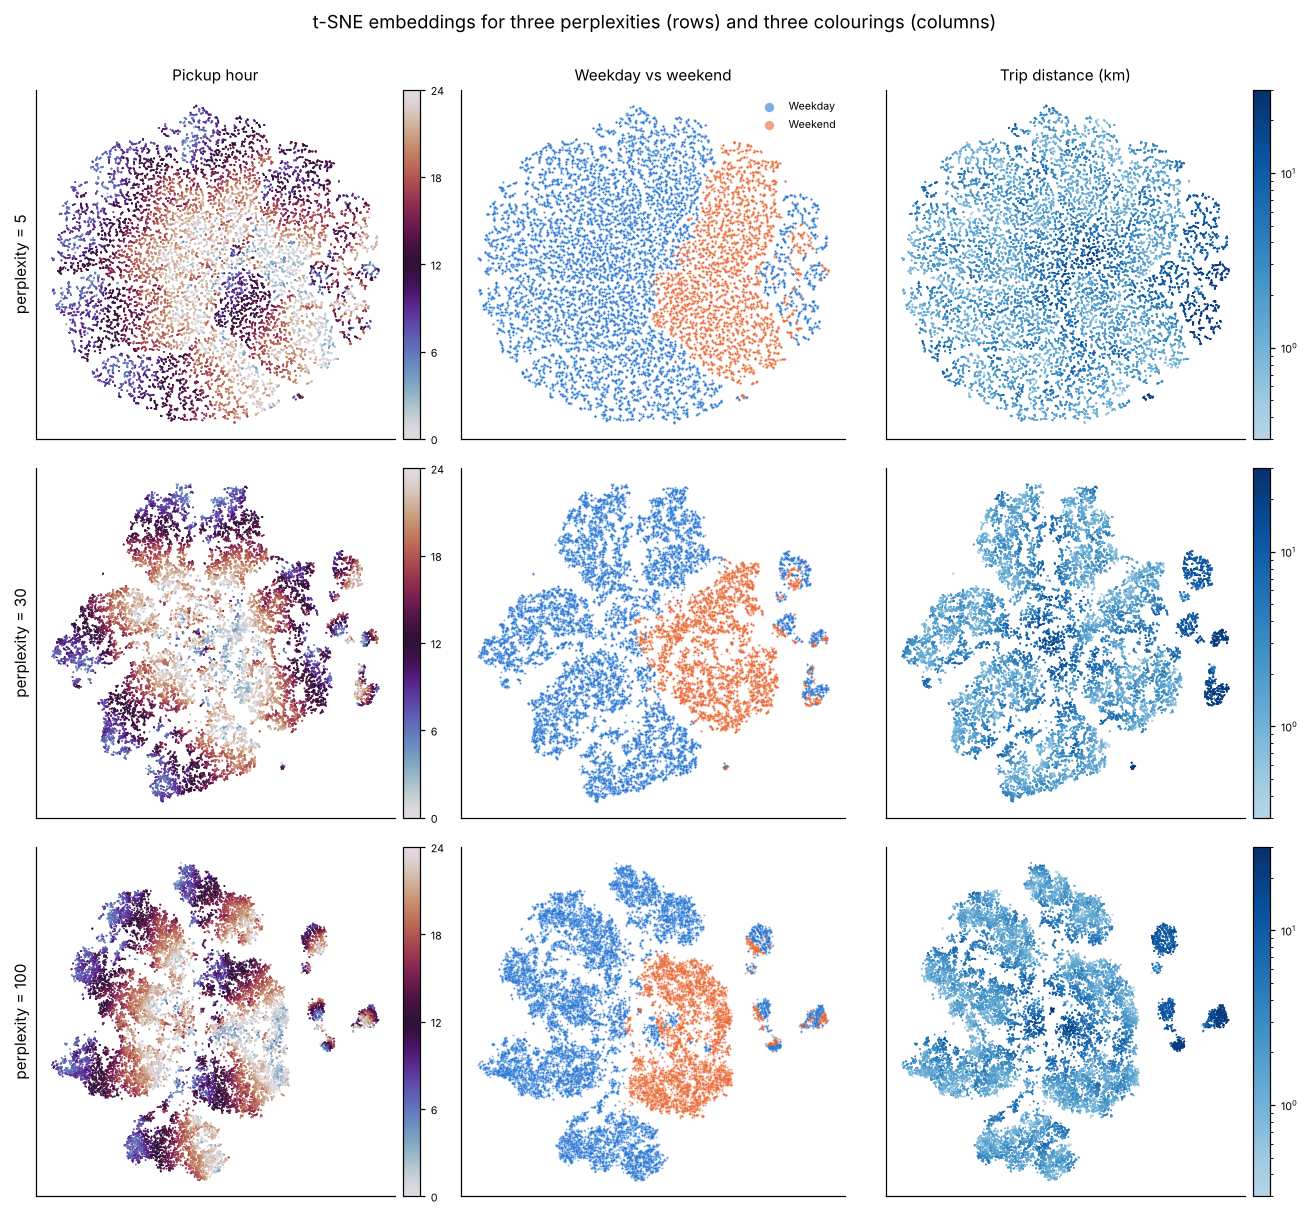

In [27]:
fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for r, p in enumerate(PERPLEXITIES):
    for c, (key, label) in enumerate(COLOURINGS.items()):
        sc = plot_embedding(axes[r, c], TSNE_EMB[p], key, f"{label}" if r == 0 else None, legend=(r == 0))
        add_colourbar(fig, axes[r, c], sc, key)
    axes[r, 0].set_ylabel(f"perplexity = {p}", fontsize=10)
fig.suptitle("t-SNE embeddings for three perplexities (rows) and three colourings (columns)", y=1.0)
fig.tight_layout()
savefig(fig, "q6_3_tsne_grid")

## 6.4 UMAP

In [28]:
def run_umap(n_neighbors, min_dist, seed=SEED):
    t0 = time.perf_counter()
    Z = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, random_state=seed).fit_transform(X)
    return Z, time.perf_counter() - t0

N_NEIGHBORS = [5, 15, 50]
MIN_DISTS = [0.0, 0.5]
UMAP_EMB = {}
for md in MIN_DISTS:
    for nn in N_NEIGHBORS:
        UMAP_EMB[(nn, md)], RUNTIME[f"UMAP n_neighbors={nn}, min_dist={md}"] = run_umap(nn, md)
        print(f"UMAP n_neighbors={nn}, min_dist={md}: {RUNTIME[f'UMAP n_neighbors={nn}, min_dist={md}']:.1f} s")

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP n_neighbors=5, min_dist=0.0: 25.2 s


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP n_neighbors=15, min_dist=0.0: 10.8 s


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


...

UMAP n_neighbors=5, min_dist=0.5: 5.9 s


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP n_neighbors=15, min_dist=0.5: 10.0 s


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP n_neighbors=50, min_dist=0.5: 18.4 s


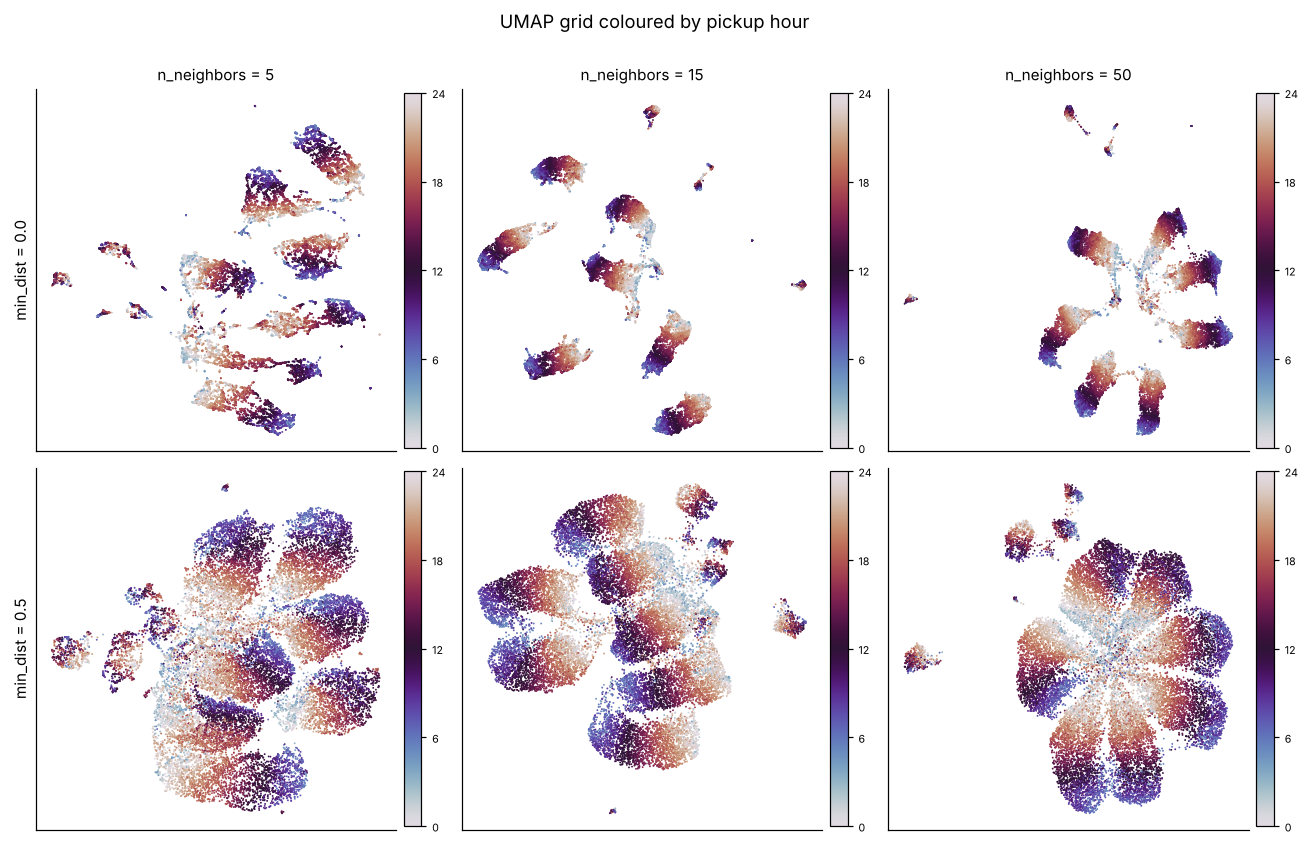

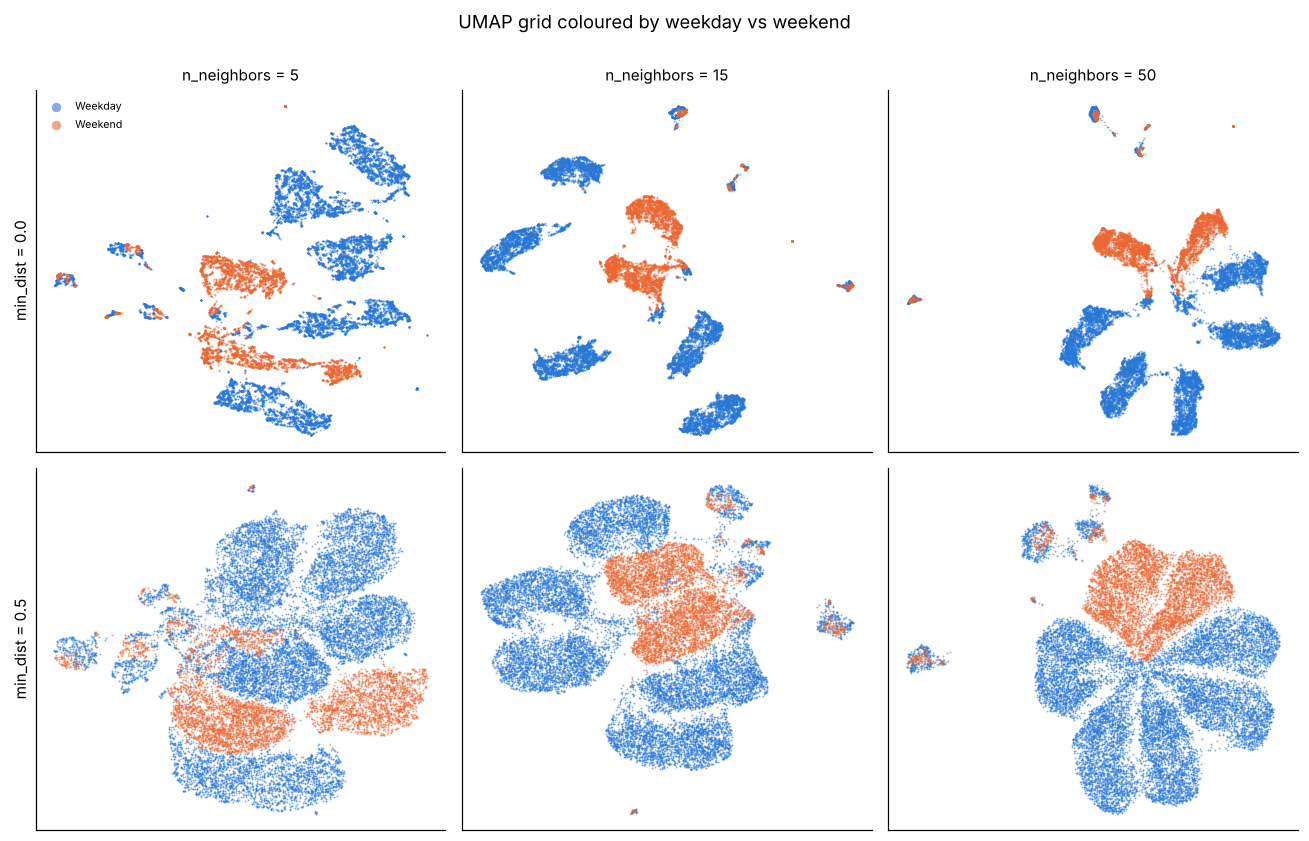

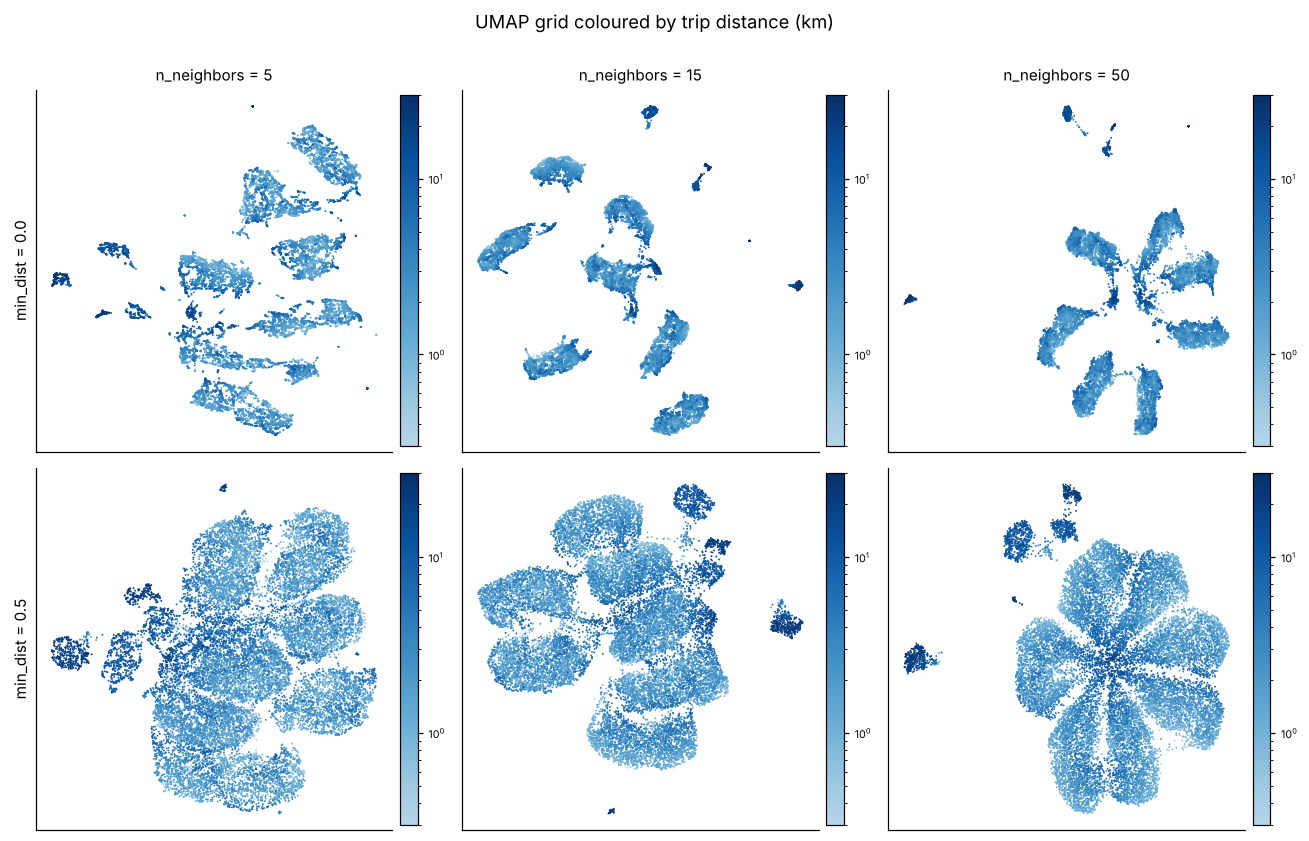

In [29]:
for key, label in COLOURINGS.items():
    fig, axes = plt.subplots(2, 3, figsize=(12, 7.6))
    for r, md in enumerate(MIN_DISTS):
        for c, nn in enumerate(N_NEIGHBORS):
            sc = plot_embedding(axes[r, c], UMAP_EMB[(nn, md)], key, f"n_neighbors = {nn}" if r == 0 else None,
                                legend=(r == 0 and c == 0))
            add_colourbar(fig, axes[r, c], sc, key)
        axes[r, 0].set_ylabel(f"min_dist = {md}", fontsize=10)
    fig.suptitle(f"UMAP grid coloured by {label.lower()}", y=1.0)
    fig.tight_layout()
    savefig(fig, f"q6_4_umap_grid_{key}")

### Choosing the best 2D embedding
Both are scored on the same fixed subset of 3,000 trips: trustworthiness at k = 15 (local structure), and the Spearman correlation between pairwise distances in the scaled feature space and in the embedding (global structure).

In [30]:
EVAL_IDX = np.random.default_rng(SEED).choice(len(X), 3000, replace=False)
D_HIGH = pdist(X[EVAL_IDX])

def structure_scores(Z):
    tw = trustworthiness(X[EVAL_IDX], Z[EVAL_IDX], n_neighbors=15)
    rho = spearmanr(D_HIGH, pdist(Z[EVAL_IDX])).statistic
    return tw, rho

rows = []
for p in PERPLEXITIES:
    rows.append(("t-SNE", f"perplexity={p}", *structure_scores(TSNE_EMB[p])))
for (nn, md), Z in UMAP_EMB.items():
    rows.append(("UMAP", f"n_neighbors={nn}, min_dist={md}", *structure_scores(Z)))
rows.append(("PCA", "PC1-PC2", *structure_scores(Z_pca)))
scores = pd.DataFrame(rows, columns=["method", "setting", "trustworthiness_k15", "spearman_global"])
scores["mean"] = scores[["trustworthiness_k15", "spearman_global"]].mean(axis=1)
print(scores.round(3).to_string(index=False))

best_tsne_row = scores[scores.method == "t-SNE"].sort_values("mean", ascending=False).iloc[0]
best_umap_row = scores[scores.method == "UMAP"].sort_values("mean", ascending=False).iloc[0]
BEST_PERP = int(best_tsne_row.setting.split("=")[1])
BEST_UMAP = tuple(k for k in UMAP_EMB if f"n_neighbors={k[0]}, min_dist={k[1]}" == best_umap_row.setting)[0]
Z_tsne = TSNE_EMB[BEST_PERP]
Z_umap = UMAP_EMB[BEST_UMAP]
print(f"\nBest t-SNE: perplexity={BEST_PERP}  |  Best UMAP: n_neighbors={BEST_UMAP[0]}, min_dist={BEST_UMAP[1]}")

method                      setting  trustworthiness_k15  spearman_global  mean
 t-SNE                 perplexity=5                0.943            0.295 0.619
 t-SNE                perplexity=30                0.971            0.313 0.642
 t-SNE               perplexity=100                0.978            0.357 0.667
  UMAP  n_neighbors=5, min_dist=0.0                0.953            0.319 0.636
  UMAP n_neighbors=15, min_dist=0.0                0.960            0.368 0.664
  UMAP n_neighbors=50, min_dist=0.0                0.964            0.461 0.713
  UMAP  n_neighbors=5, min_dist=0.5                0.916            0.294 0.605
  UMAP n_neighbors=15, min_dist=0.5                0.929            0.353 0.641
  UMAP n_neighbors=50, min_dist=0.5                0.928            0.387 0.658
   PCA                      PC1-PC2                0.758            0.766 0.762

Best t-SNE: perplexity=100  |  Best UMAP: n_neighbors=50, min_dist=0.0


## 6.5 Density-based clustering
DBSCAN in each space. `min_samples` is fixed first, and `eps` is read off the k-distance curve (k = `min_samples`) at its knee, the point furthest from the straight line joining the curve's ends.

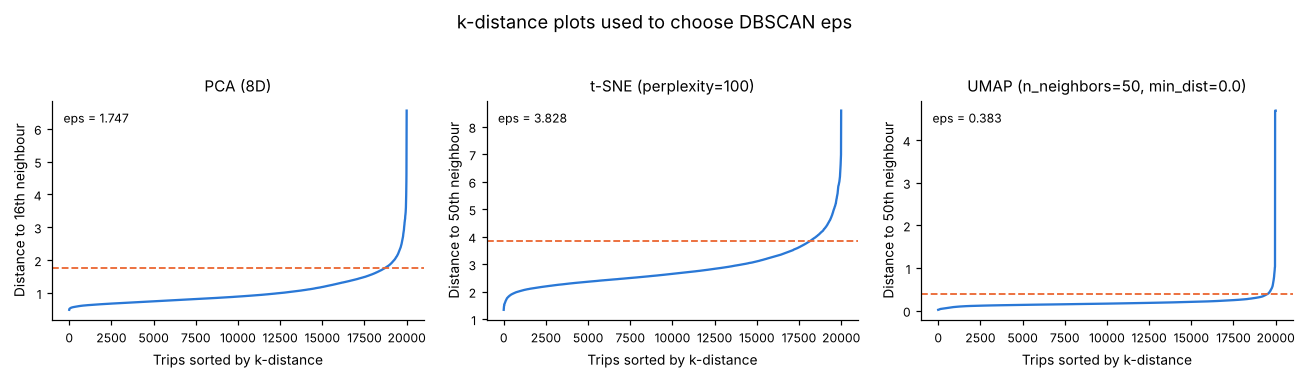

                              space  min_samples   eps  clusters  noise_fraction
                           PCA (8D)           16 1.747         3           0.022
             t-SNE (perplexity=100)           50 3.828        10           0.011
UMAP (n_neighbors=50, min_dist=0.0)           50 0.383        13           0.008


In [31]:
def knee_eps(kdist):
    y = np.sort(kdist)
    x = np.linspace(0, 1, len(y))
    yn = (y - y[0]) / (y[-1] - y[0])
    return y[np.argmax(x - yn)]

def k_distance(Z, k):
    d, _ = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z)
    return d[:, -1]

SPACES = {f"PCA ({K90}D)": Z_pca90, f"t-SNE (perplexity={BEST_PERP})": Z_tsne,
          f"UMAP (n_neighbors={BEST_UMAP[0]}, min_dist={BEST_UMAP[1]})": Z_umap}
MIN_SAMPLES = {f"PCA ({K90}D)": 2 * K90, f"t-SNE (perplexity={BEST_PERP})": 50,
               f"UMAP (n_neighbors={BEST_UMAP[0]}, min_dist={BEST_UMAP[1]})": 50}

KDIST, EPS, LABELS = {}, {}, {}
for name, Z in SPACES.items():
    k = MIN_SAMPLES[name]
    KDIST[name] = k_distance(Z, k)
    EPS[name] = knee_eps(KDIST[name])
    LABELS[name] = DBSCAN(eps=EPS[name], min_samples=k).fit_predict(Z)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, (name, kd) in zip(axes, KDIST.items()):
    ax.plot(np.sort(kd), color=WEEKDAY_C, lw=1.5)
    ax.axhline(EPS[name], color=WEEKEND_C, ls="--", lw=1.2)
    ax.text(0.03, 0.9, f"eps = {EPS[name]:.3f}", transform=ax.transAxes, fontsize=8)
    ax.set_title(name)
    ax.set_xlabel("Trips sorted by k-distance")
    ax.set_ylabel(f"Distance to {MIN_SAMPLES[name]}th neighbour")
fig.suptitle("k-distance plots used to choose DBSCAN eps", y=1.03)
fig.tight_layout()
savefig(fig, "q6_5_kdistance")

summary = pd.DataFrame([{"space": n, "min_samples": MIN_SAMPLES[n], "eps": EPS[n],
                         "clusters": len(set(l) - {-1}), "noise_fraction": np.mean(l == -1)} for n, l in LABELS.items()])
print(summary.round(3).to_string(index=False))

In [32]:
def circular_mean_hour(h):
    ang = 2 * np.pi * h / 24
    return (np.degrees(np.arctan2(np.sin(ang).mean(), np.cos(ang).mean())) / 15) % 24

LGA = (40.7769, -73.8740)
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sample["jfk_ewr_pickup"] = sample.near_jfk_pickup | sample.near_ewr_pickup
sample["jfk_ewr_dropoff"] = sample.near_jfk_dropoff | sample.near_ewr_dropoff
sample["lga_pickup"] = haversine_np(sample.pickup_longitude, sample.pickup_latitude, LGA[1], LGA[0]) <= AIRPORT_RADIUS_KM
sample["lga_dropoff"] = haversine_np(sample.dropoff_longitude, sample.dropoff_latitude, LGA[1], LGA[0]) <= AIRPORT_RADIUS_KM

def area(lat, lon):
    if -74.02 < lon < -73.93 and lat > 40.70:
        return "Manhattan"
    if lat < 40.70 and lon > -74.03:
        return "Brooklyn"
    return "Queens"

def describe(p):
    when = ("late-night" if (p.circ_hour >= 21 or p.circ_hour < 5) else
            "morning" if p.circ_hour < 11 else "midday" if p.circ_hour < 16 else "evening")
    to_area = area(p.median_dropoff_lat, p.median_dropoff_lon)
    from_area = area(p.median_pickup_lat, p.median_pickup_lon)
    if p.jfk_ewr_pickup > 0.5:
        return f"JFK/Newark pickups to {to_area}"
    if p.jfk_ewr_dropoff > 0.5:
        return f"{from_area} rides to JFK/Newark"
    if p.lga_pickup > 0.5:
        return f"LaGuardia pickups to {to_area}"
    if p.lga_dropoff > 0.5:
        return f"{from_area} rides to LaGuardia"
    length = "short" if p.median_distance_km < 1.8 else "medium" if p.median_distance_km < 4.5 else "long"
    if p.top_day_share > 0.8:
        prefix = "late-night " if when == "late-night" else ""
        return f"{prefix}{DAYS[int(p.top_day)]} {from_area} trips"
    days = "weekend" if p.weekend_share > 0.6 else "weekday" if p.weekend_share < 0.15 else "all-week"
    where = from_area if from_area == to_area else f"{from_area}-to-{to_area}"
    return f"{when} {days} {length} {where} trips"

def profile(labels):
    d = sample.assign(cluster=labels)
    d = d[d.cluster != -1]
    g = d.groupby("cluster")
    p = pd.DataFrame({
        "trips": g.size(),
        "share_of_sample": g.size() / len(sample),
        "median_distance_km": g.distance_km.median(),
        "median_duration_min": g.trip_duration.median() / 60,
        "median_speed_kmh": g.speed_kmh.median(),
        "circ_hour": g.pickup_hour.apply(circular_mean_hour),
        "weekend_share": g.is_weekend.mean(),
        "top_day": g.pickup_dow.agg(lambda x: x.mode().iloc[0]),
        "top_day_share": g.pickup_dow.agg(lambda x: x.value_counts(normalize=True).iloc[0]),
        "airport_share": g.airport_trip.mean(),
        "jfk_ewr_pickup": g.jfk_ewr_pickup.mean(),
        "jfk_ewr_dropoff": g.jfk_ewr_dropoff.mean(),
        "lga_pickup": g.lga_pickup.mean(),
        "lga_dropoff": g.lga_dropoff.mean(),
        "median_pickup_lat": g.pickup_latitude.median(),
        "median_pickup_lon": g.pickup_longitude.median(),
        "median_dropoff_lat": g.dropoff_latitude.median(),
        "median_dropoff_lon": g.dropoff_longitude.median(),
    })
    p["name"] = p.apply(describe, axis=1)
    return p.sort_values("trips", ascending=False)

PROFILES = {}
for name, l in LABELS.items():
    PROFILES[name] = profile(l)
    print(f"\n=== {name} ===")
    print(PROFILES[name].drop(columns=["median_pickup_lat", "median_pickup_lon", "median_dropoff_lat", "median_dropoff_lon", "top_day"]).round(2).to_string())
    PROFILES[name].round(3).to_csv(f"{FIG_DIR}/q6_5_profiles_{name.split(' ')[0].lower()}.csv")


=== PCA (8D) ===
         trips  share_of_sample  median_distance_km  median_duration_min  median_speed_kmh  circ_hour  weekend_share  top_day_share  airport_share  jfk_ewr_pickup  jfk_ewr_dropoff  lga_pickup  lga_dropoff                                     name
cluster                                                                                                                                                                                                                                              
0        19091            0.950               2.020               10.550            12.610     16.600          0.280          0.150          0.000           0.000            0.000       0.030        0.010  evening all-week medium Manhattan trips
1          294            0.010              20.320               43.610            26.920     17.950          0.280          0.170          0.980           0.980            0.000       0.000        0.000          JFK/Newark pickups to Manhatta

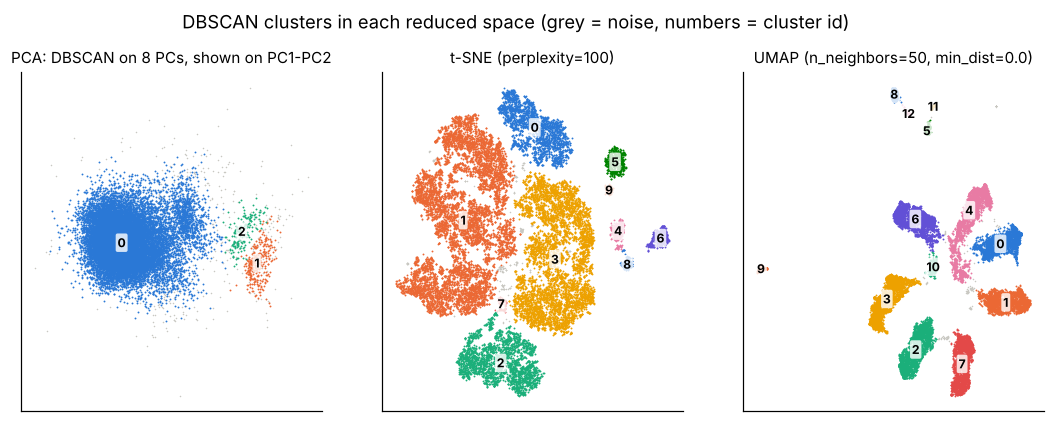

In [33]:
def plot_clusters(ax, Z, labels, title):
    noise = labels == -1
    ax.scatter(Z[noise, 0], Z[noise, 1], c=GREY_C, s=1, lw=0, rasterized=True)
    for i, c in enumerate(sorted(set(labels) - {-1})):
        m = labels == c
        ax.scatter(Z[m, 0], Z[m, 1], c=CLUSTER_COLORS[i % len(CLUSTER_COLORS)], s=1.5, lw=0, rasterized=True)
        cx, cy = np.median(Z[m, 0]), np.median(Z[m, 1])
        ax.text(cx, cy, str(c), fontsize=8, fontweight="bold", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
plot_clusters(axes[0], Z_pca, LABELS[f"PCA ({K90}D)"], f"PCA: DBSCAN on {K90} PCs, shown on PC1-PC2")
plot_clusters(axes[1], Z_tsne, LABELS[f"t-SNE (perplexity={BEST_PERP})"], f"t-SNE (perplexity={BEST_PERP})")
plot_clusters(axes[2], Z_umap, LABELS[f"UMAP (n_neighbors={BEST_UMAP[0]}, min_dist={BEST_UMAP[1]})"],
              f"UMAP (n_neighbors={BEST_UMAP[0]}, min_dist={BEST_UMAP[1]})")
fig.suptitle("DBSCAN clusters in each reduced space (grey = noise, numbers = cluster id)", y=1.02)
savefig(fig, "q6_5_clusters")

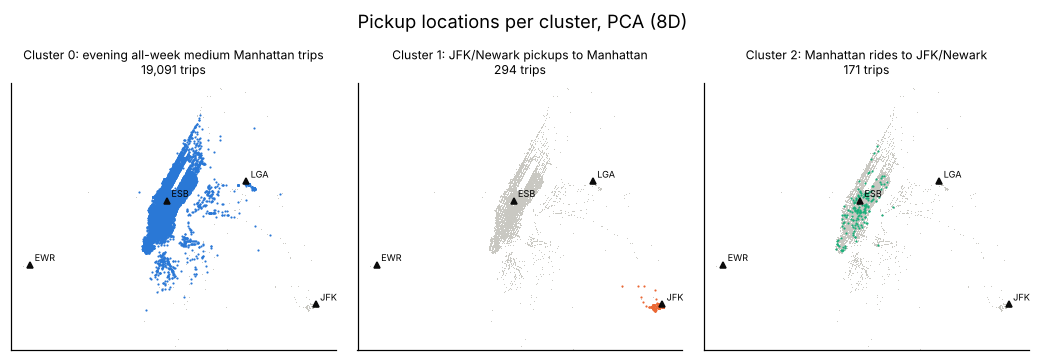

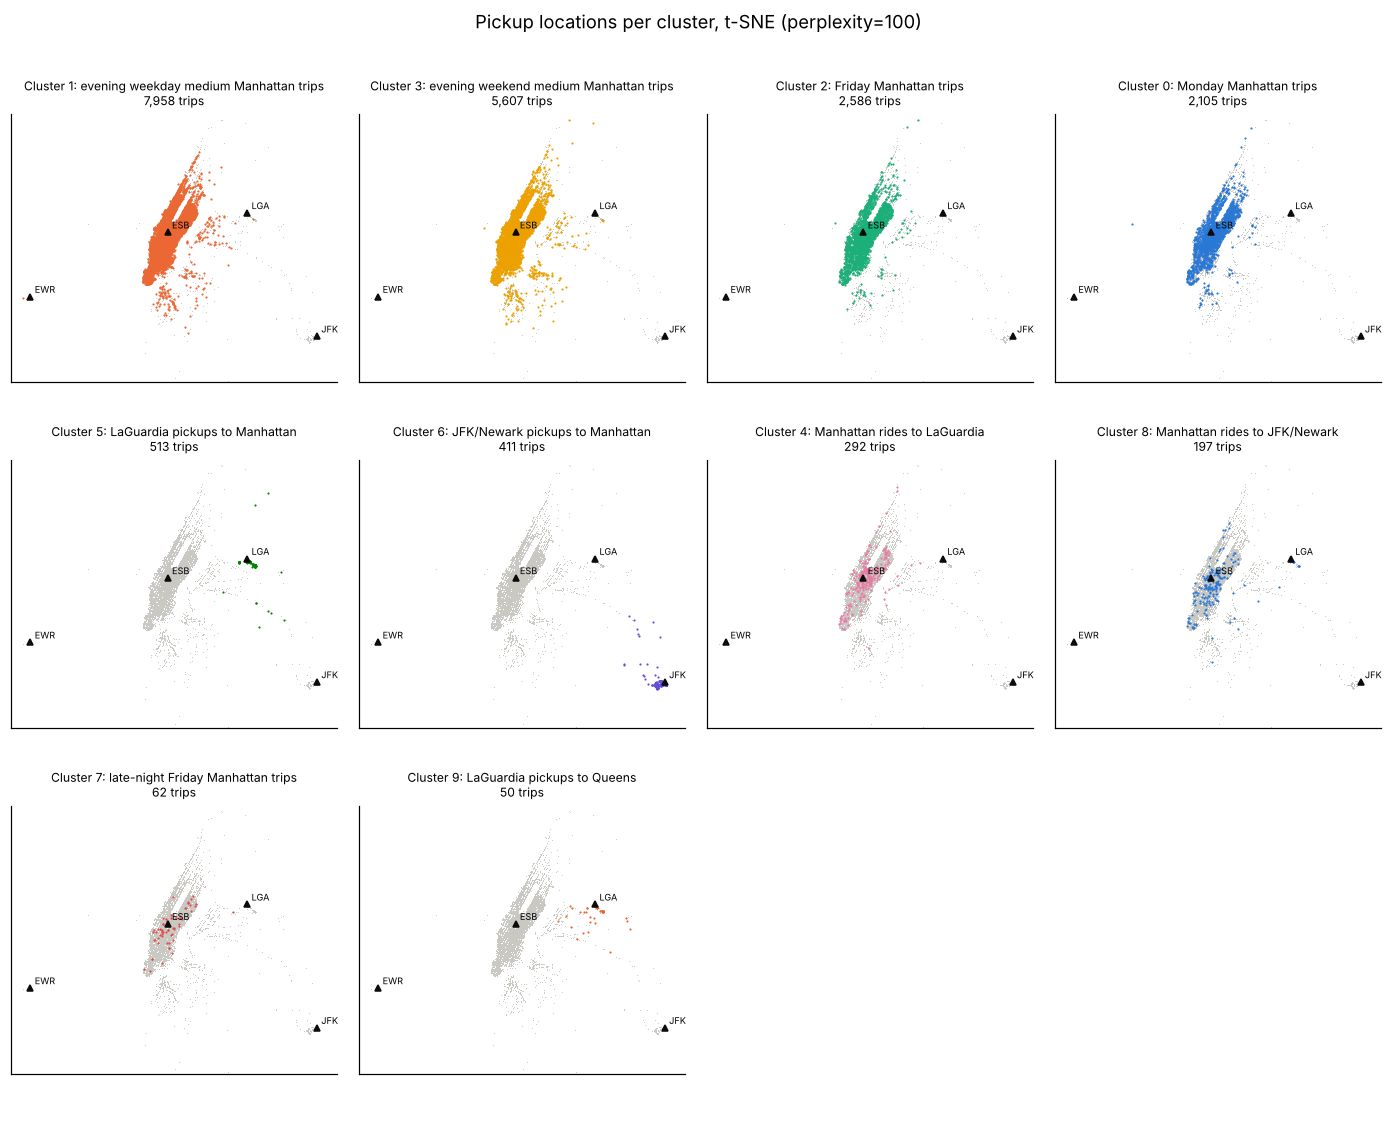

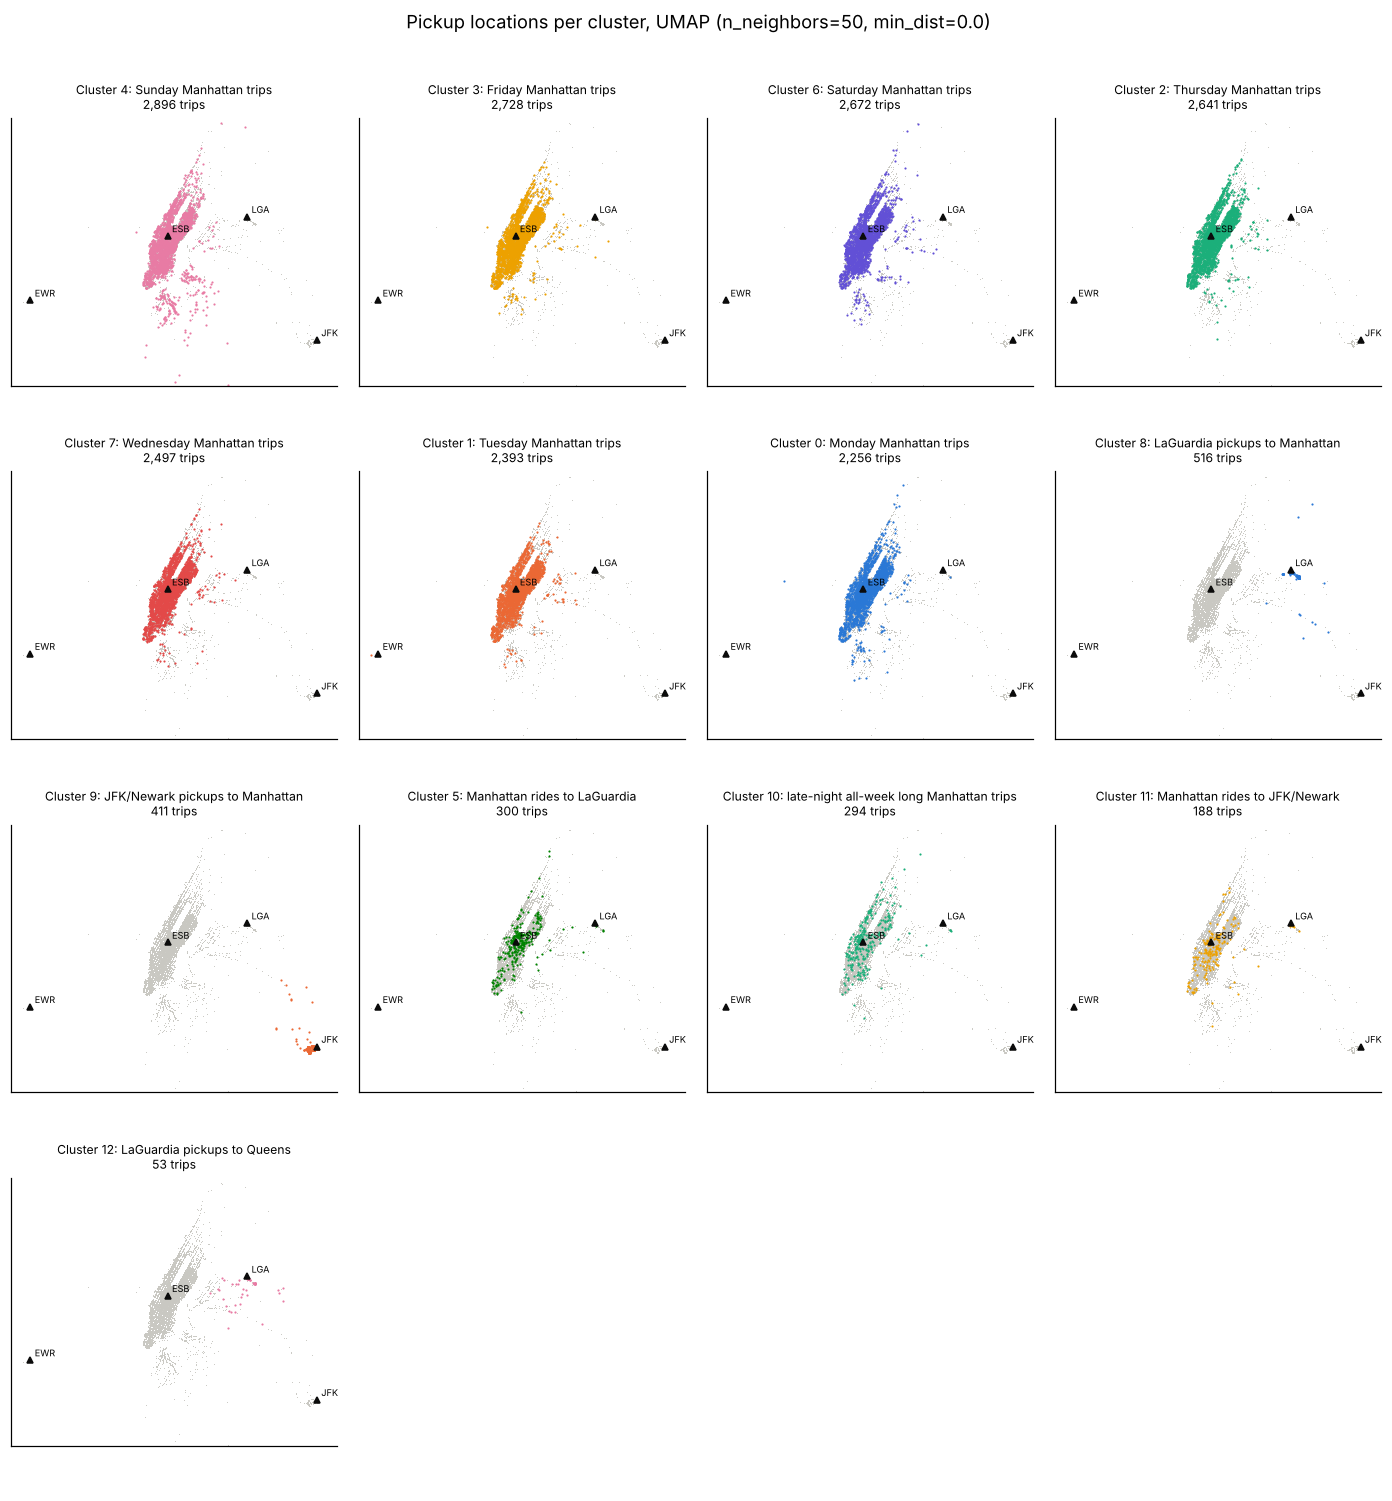

In [34]:
LANDMARKS = {"ESB": (40.756724, -73.983806), "JFK": JFK, "EWR": EWR, "LGA": (40.7769, -73.8740)}

def cluster_maps(name, labels):
    prof = PROFILES[name]
    n = len(prof)
    cols = min(4, max(n, 1))
    rows = int(np.ceil(n / cols)) if n else 1
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.4 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (c, p) in zip(axes.ravel(), prof.iterrows()):
        ax.axis("on")
        ax.scatter(sample.pickup_longitude, sample.pickup_latitude, c=GREY_C, s=0.4, lw=0, rasterized=True)
        m = labels == c
        ax.scatter(sample.pickup_longitude[m], sample.pickup_latitude[m], c=CLUSTER_COLORS[sorted(set(labels) - {-1}).index(c) % 8],
                   s=2, lw=0, rasterized=True)
        for lm, (la, lo) in LANDMARKS.items():
            ax.plot(lo, la, marker="^", color="#0b0b0b", ms=4)
            ax.text(lo + 0.006, la + 0.004, lm, fontsize=6)
        ax.set_xlim(-74.2, -73.75)
        ax.set_ylim(40.6, 40.88)
        ax.set_aspect(1 / np.cos(np.radians(40.75)))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"Cluster {c}: {p['name']}\n{int(p.trips):,} trips", fontsize=8)
    fig.suptitle(f"Pickup locations per cluster, {name}", y=1.0)
    fig.tight_layout()
    return fig

for i, (name, l) in enumerate(LABELS.items()):
    savefig(cluster_maps(name, l), f"q6_5_maps_{['pca', 'tsne', 'umap'][i]}")

## 6.6 Comparison

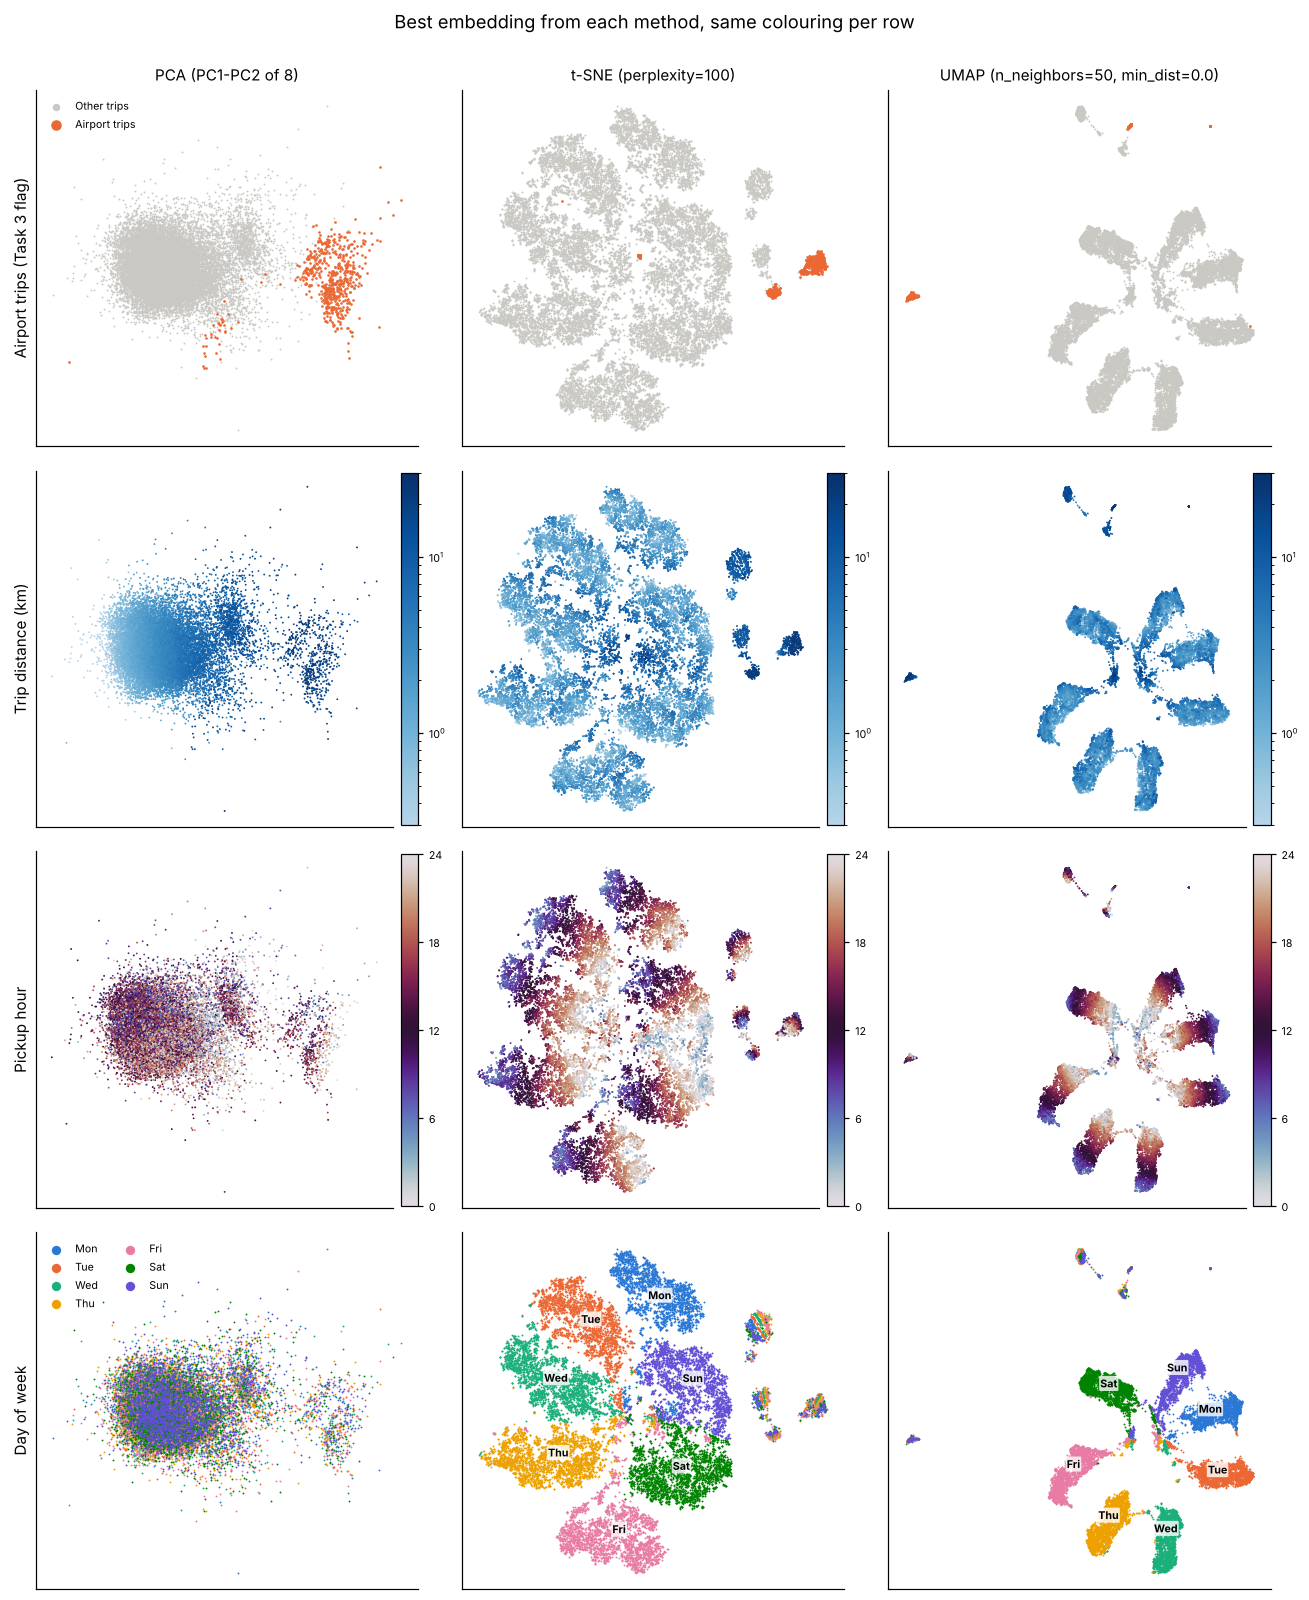

In [35]:
BEST = {f"PCA (PC1-PC2 of {K90})": Z_pca, f"t-SNE (perplexity={BEST_PERP})": Z_tsne,
        f"UMAP (n_neighbors={BEST_UMAP[0]}, min_dist={BEST_UMAP[1]})": Z_umap}
def plot_dow(ax, Z, title=None, text=True):
    for d in range(7):
        m = sample.pickup_dow.values == d
        ax.scatter(Z[m, 0], Z[m, 1], c=CLUSTER_COLORS[d], s=1.5, lw=0, rasterized=True, label=DAYS[d][:3])
        if text:
            ax.text(np.median(Z[m, 0]), np.median(Z[m, 1]), DAYS[d][:3], fontsize=7, fontweight="bold", ha="center",
                    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.8))
    if not text:
        ax.legend(frameon=False, fontsize=7, markerscale=5, ncol=2, loc="upper left")
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title)

ROWS = {"airport": "Airport trips (Task 3 flag)", "distance": "Trip distance (km)", "hour": "Pickup hour", "dow": "Day of week"}
fig, axes = plt.subplots(4, 3, figsize=(12, 14.5))
for r, (key, label) in enumerate(ROWS.items()):
    for c, (name, Z) in enumerate(BEST.items()):
        if key == "dow":
            plot_dow(axes[r, c], Z, text=(c != 0))
        else:
            sc = plot_embedding(axes[r, c], Z, key, name if r == 0 else None, legend=(c == 0))
            add_colourbar(fig, axes[r, c], sc, key)
    axes[r, 0].set_ylabel(label, fontsize=10)
fig.suptitle("Best embedding from each method, same colouring per row", y=1.0)
fig.tight_layout()
savefig(fig, "q6_6_side_by_side")

In [36]:
airport = sample.airport_trip.values
rows = []
for name, l in LABELS.items():
    ap_labels = l[airport]
    ap_clustered = ap_labels[ap_labels != -1]
    top = pd.Series(ap_clustered).value_counts()
    top_c = top.index[0] if len(top) else None
    rows.append({"space": name,
                 "airport_trips_in_noise": np.mean(ap_labels == -1),
                 "largest_share_in_one_cluster": (top.iloc[0] / airport.sum()) if len(top) else 0,
                 "that_cluster": top_c,
                 "airport_share_of_that_cluster": airport[l == top_c].mean() if top_c is not None else np.nan})
airport_tab = pd.DataFrame(rows)
print(f"Airport trips in sample: {airport.sum()}")
print(airport_tab.round(3).to_string(index=False))

Airport trips in sample: 598
                              space  airport_trips_in_noise  largest_share_in_one_cluster  that_cluster  airport_share_of_that_cluster
                           PCA (8D)                   0.261                         0.483             1                          0.983
             t-SNE (perplexity=100)                   0.055                         0.666             6                          0.968
UMAP (n_neighbors=50, min_dist=0.0)                   0.055                         0.666             9                          0.968


In [37]:
names = list(LABELS)
ari_rows = []
for i in range(3):
    for j in range(i + 1, 3):
        a, b = LABELS[names[i]], LABELS[names[j]]
        both = (a != -1) & (b != -1)
        ari_rows.append({"pair": f"{names[i].split(' ')[0]} vs {names[j].split(' ')[0]}",
                         "ARI_all_points_noise_as_label": adjusted_rand_score(a, b),
                         "ARI_points_clustered_by_both": adjusted_rand_score(a[both], b[both]) if both.sum() else np.nan,
                         "points_clustered_by_both": both.mean()})
ari = pd.DataFrame(ari_rows)
print(ari.round(3).to_string(index=False))

         pair  ARI_all_points_noise_as_label  ARI_points_clustered_by_both  points_clustered_by_both
 PCA vs t-SNE                          0.054                         0.037                     0.970
  PCA vs UMAP                          0.021                         0.014                     0.972
t-SNE vs UMAP                          0.480                         0.490                     0.983


In [38]:
def neighbour_agreement(labels, k=15):
    m = labels != -1
    _, nbr = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X[m])
    same = (labels[nbr[:, 1:]] == labels[m][:, None]).mean()
    rng = np.random.default_rng(SEED)
    base = np.mean([(rng.permutation(labels[m]) == labels[m]).mean() for _ in range(20)])
    return same, base

trust = pd.DataFrame([{"space": n, **dict(zip(["same_label_among_15_original_neighbours", "chance_level"],
                                              neighbour_agreement(l)))} for n, l in LABELS.items()])
print("Do clusters hold up in the original 11-D feature space?")
print(trust.round(3).to_string(index=False))

for name, l in LABELS.items():
    m = l != -1
    print(f"{name}: ARI(cluster, day of week) = {adjusted_rand_score(l[m], sample.pickup_dow.values[m]):.3f}")

Do clusters hold up in the original 11-D feature space?
                              space  same_label_among_15_original_neighbours  chance_level
                           PCA (8D)                                    0.998         0.953
             t-SNE (perplexity=100)                                    0.970         0.272
UMAP (n_neighbors=50, min_dist=0.0)                                    0.957         0.121
PCA (8D): ARI(cluster, day of week) = 0.000
t-SNE (perplexity=100): ARI(cluster, day of week) = 0.453
UMAP (n_neighbors=50, min_dist=0.0): ARI(cluster, day of week) = 0.827


### Check: UMAP without the day-of-week features

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Clusters: 6, noise: 0.007
         trips  median_distance_km  median_duration_min  circ_hour  weekend_share  airport_share                                                name
cluster                                                                                                                                             
0        18266               1.930               10.080     16.660          0.290          0.000             evening all-week medium Manhattan trips
2          514               9.780               30.480     16.580          0.250          0.000                      LaGuardia pickups to Manhattan
3          413              19.850               39.120     17.990          0.280          0.960                     JFK/Newark pickups to Manhattan
1          324               9.510               24.560     11.300          0.270          0.000                        Manhattan rides to LaGuardia
4          188              20.280               40.480     11.820          0.30

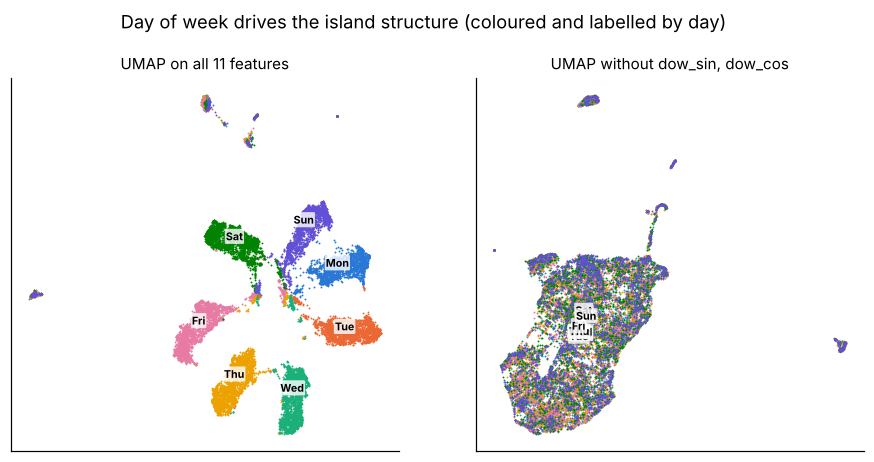

In [39]:
NO_DOW = [i for i, f in enumerate(FEATURES) if not f.startswith("dow")]
t0 = time.perf_counter()
Z_umap_nodow = umap.UMAP(n_neighbors=BEST_UMAP[0], min_dist=BEST_UMAP[1], random_state=SEED).fit_transform(X[:, NO_DOW])
RUNTIME["UMAP without day-of-week"] = time.perf_counter() - t0
umap_name = [n for n in LABELS if n.startswith("UMAP")][0]
labels_nodow = DBSCAN(eps=knee_eps(k_distance(Z_umap_nodow, MIN_SAMPLES[umap_name])),
                      min_samples=MIN_SAMPLES[umap_name]).fit_predict(Z_umap_nodow)
prof_nodow = profile(labels_nodow)
print(f"Clusters: {len(set(labels_nodow) - {-1})}, noise: {np.mean(labels_nodow == -1):.3f}")
print(prof_nodow[["trips", "median_distance_km", "median_duration_min", "circ_hour", "weekend_share", "airport_share", "name"]].round(2).to_string())
print(f"ARI vs UMAP clusters with day of week: {adjusted_rand_score(LABELS[umap_name], labels_nodow):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
plot_dow(axes[0], Z_umap, "UMAP on all 11 features")
plot_dow(axes[1], Z_umap_nodow, "UMAP without dow_sin, dow_cos")
fig.suptitle("Day of week drives the island structure (coloured and labelled by day)", y=1.02)
savefig(fig, "q6_6_umap_without_dow")

### Seed sensitivity

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


             method  seed vs 42  procrustes_disparity  knn15_overlap  clusters  ARI_vs_seed42_clusters
              t-SNE           0                 0.000          1.000        10                   1.000
              t-SNE           7                 0.000          1.000        10                   1.000
t-SNE (random init)           0                 0.102          0.757        12                   0.612
t-SNE (random init)           7                 0.132          0.735         8                   0.761
               UMAP           0                 0.111          0.433        11                   0.800
               UMAP           7                 0.328          0.409         9                   0.710


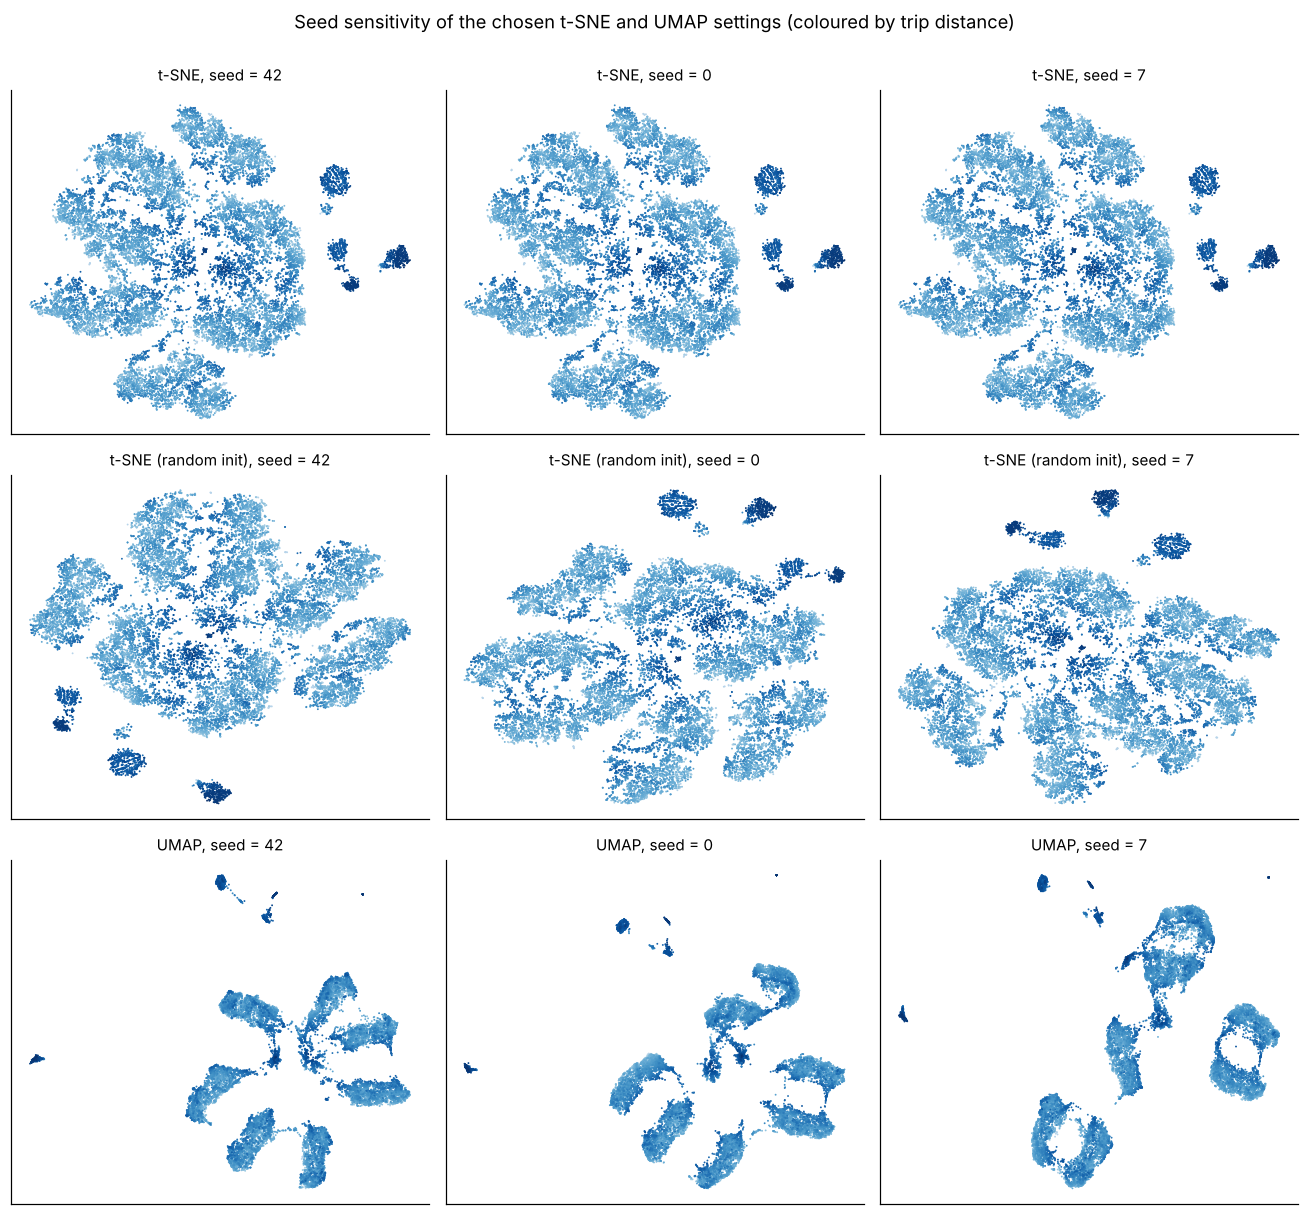

In [40]:
SEEDS = [42, 0, 7]
seed_runs = {"t-SNE": {42: Z_tsne}, "t-SNE (random init)": {}, "UMAP": {42: Z_umap}}
seed_runs["t-SNE (random init)"][42], RUNTIME[f"t-SNE perplexity={BEST_PERP}, random init, seed=42"] = run_tsne(BEST_PERP, 42, "random")
for s in SEEDS[1:]:
    seed_runs["t-SNE"][s], RUNTIME[f"t-SNE perplexity={BEST_PERP}, seed={s}"] = run_tsne(BEST_PERP, s)
    seed_runs["t-SNE (random init)"][s], RUNTIME[f"t-SNE perplexity={BEST_PERP}, random init, seed={s}"] = run_tsne(BEST_PERP, s, "random")
    seed_runs["UMAP"][s], RUNTIME[f"UMAP n_neighbors={BEST_UMAP[0]}, min_dist={BEST_UMAP[1]}, seed={s}"] = run_umap(*BEST_UMAP, seed=s)

def knn_overlap(Za, Zb, k=15):
    _, na = NearestNeighbors(n_neighbors=k + 1).fit(Za).kneighbors(Za)
    _, nb = NearestNeighbors(n_neighbors=k + 1).fit(Zb).kneighbors(Zb)
    return np.mean([len(set(a[1:]) & set(b[1:])) / k for a, b in zip(na, nb)])

def dbscan_rule(Z, k):
    return DBSCAN(eps=knee_eps(k_distance(Z, k)), min_samples=k).fit_predict(Z)

seed_rows = []
for method, runs in seed_runs.items():
    name = [n for n in LABELS if n.startswith(method.split(" ")[0])][0]
    base = dbscan_rule(runs[42], MIN_SAMPLES[name])
    for s in SEEDS[1:]:
        Zs = runs[s]
        ls = dbscan_rule(Zs, MIN_SAMPLES[name])
        seed_rows.append({"method": method, "seed vs 42": s,
                          "procrustes_disparity": procrustes(runs[42], Zs)[2],
                          "knn15_overlap": knn_overlap(runs[42], Zs),
                          "clusters": len(set(ls) - {-1}),
                          "ARI_vs_seed42_clusters": adjusted_rand_score(base, ls)})
seed_tab = pd.DataFrame(seed_rows)
print(seed_tab.round(3).to_string(index=False))

fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for r, (method, runs) in enumerate(seed_runs.items()):
    for c, s in enumerate(SEEDS):
        plot_embedding(axes[r, c], runs[s], "distance", f"{method}, seed = {s}")
fig.suptitle("Seed sensitivity of the chosen t-SNE and UMAP settings (coloured by trip distance)", y=1.0)
fig.tight_layout()
savefig(fig, "q6_6_seeds")

In [41]:
runtime = pd.Series(RUNTIME, name="seconds").round(1)
print(runtime.to_string())

PCA                                            0.100
t-SNE perplexity=5                            85.100
t-SNE perplexity=30                          100.500
t-SNE perplexity=100                         159.700
UMAP n_neighbors=5, min_dist=0.0              25.200
UMAP n_neighbors=15, min_dist=0.0             10.800
UMAP n_neighbors=50, min_dist=0.0             18.400
UMAP n_neighbors=5, min_dist=0.5               5.900
UMAP n_neighbors=15, min_dist=0.5             10.000
UMAP n_neighbors=50, min_dist=0.5             18.400
UMAP without day-of-week                      17.800
t-SNE perplexity=100, random init, seed=42   149.700
t-SNE perplexity=100, seed=0                 148.500
t-SNE perplexity=100, random init, seed=0    124.900
UMAP n_neighbors=50, min_dist=0.0, seed=0     17.700
t-SNE perplexity=100, seed=7                 151.700
t-SNE perplexity=100, random init, seed=7    140.500
UMAP n_neighbors=50, min_dist=0.0, seed=7     18.200
